# 🧠 La neurona en 10 conceptos

*Creado: 2026-11-27 · Unidad 1 · Semana 1 · Material de profundización*

> 🎯 **Objetivo.** Entender **qué es una neurona artificial y por qué calcula lo que calcula**, construyendo cada pieza desde cero: primero 10 conceptos (cada uno con idea, ejemplo y 3 ejercicios), y al final un **ejemplo unificador** y un **ejercicio unificador** donde armas una neurona completa y la entrenas.

La neurona de la figura 1.02 de tu libro calcula esto:

$$z = f\!\left(w^{\top}x + b\right)$$

Aquí $x\in\mathbb{R}^n$ son las entradas, $w\in\mathbb{R}^n$ los pesos, $b\in\mathbb{R}$ el sesgo y $f:\mathbb{R}\to\mathbb{R}$ la función de activación. Esa línea parece corta, pero guarda **diez ideas** que vamos a desarmar una por una.

## 🗺️ Mapa del cuaderno

| # | Concepto | Pregunta que responde |
|---|---|---|
| 1 | Vector y forma (`shape`) | ¿Cómo se ve un dato para una neurona? |
| 2 | Producto punto | ¿Cómo se combinan entradas y pesos? |
| 3 | Norma, ángulo y ortogonalidad | ¿Cómo medimos longitudes y perpendicularidad? |
| 4 | Hiperplano | ¿Qué "pared" describe la ecuación $w^\top x+b=0$? |
| 5 | Distancia con signo | ¿De qué lado y a qué distancia de la pared está un punto? |
| 6 | Sesgo $b$ | ¿Por qué hace falta y qué mueve? |
| 7 | Función de activación | ¿Qué hace $f$ con ese número? |
| 8 | Lotes y forma matricial | ¿Cómo procesamos muchos datos a la vez? |
| 9 | Función de pérdida | ¿Cómo medimos qué tan mal lo hace la neurona? |
| 10 | Gradiente y descenso | ¿Cómo se ajustan $w$ y $b$ para hacerlo mejor? |
| 🏁 | **Ejemplo unificador** | Una neurona completa, paso a paso, entrenada con datos |
| 🏆 | **Ejercicio unificador** | La construyes tú, y descubres su límite (XOR) |

## 🔁 Cómo funciona cada concepto

1. 🎯 **Objetivo**: qué vas a lograr.
2. 💡 **Idea básica**, contada con calma y con su base matemática.
3. 👀 **Ejemplo resuelto**: solo lo ejecutas y observas.
4. ✏️ **3 ejercicios** con espacios `___` que rellenas. Cada uno termina con una celda de verificación que imprime ✅ o ❌.
5. 🏷️ **Estatus** de lo que afirmamos (para no confundir cosas distintas):

| Etiqueta | Significa |
|---|---|
| 📘 **Definición** | Es una convención: se define así. |
| 🟦 **Teorema** | Está demostrado. |
| 🟨 **Heurística** | Una regla que suele servir, sin garantía general. |
| 🟧 **Práctica empírica** | Funciona bien en la práctica; no está demostrado que sea lo mejor. |

## 💻 Cómo trabajarlo en PyCharm

- Ejecuta **celda por celda** con `Shift + Enter`, de arriba hacia abajo. El estado se conserva entre celdas (el *kernel* recuerda las variables).
- Un error rojo no es un fracaso: su **última línea** dice qué pasó. Los `___` sin rellenar dan `NameError`, y es normal.
- Los ejercicios son independientes entre sí dentro de cada concepto, salvo el ejercicio unificador, que se construye paso a paso.
- Si te atascas: lee el ejemplo del concepto otra vez y compara. Después de intentarlo, puedes mirar el cuaderno `_resuelto`.

## ⚙️ Preparación

Esta celda importa las herramientas y define `verificar`, una pequeña función que compara tu resultado con el esperado e imprime ✅ o ❌. **Ejecútala primero.**

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Cómo se imprimen los arreglos: 4 decimales, sin notación científica
np.set_printoptions(precision=4, suppress=True)

# Estilo de las figuras
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

def verificar(nombre, condicion):
    # Imprime ✅ si la condición es verdadera y ❌ si no
    print(("✅" if bool(condicion) else "❌"), nombre)

print("NumPy", np.__version__)

NumPy 2.5.3


---
# Concepto 1 · Vector y forma (`shape`)

> 🎯 **Objetivo.** Ver cualquier dato (una imagen, las lecturas de un sensor) como **un punto en un espacio** y saber leer su `shape`, porque la mayoría de los errores al programar redes son errores de forma.

## 💡 La idea básica

Una neurona no "ve" una foto ni "escucha" un sensor. Lo único que recibe es **una lista ordenada de números**. A esa lista la llamamos **vector**:

$$x = (x_1, x_2, \dots, x_n) \in \mathbb{R}^n$$

donde $n$ es la **dimensión** (cuántos números tiene) y cada $x_i\in\mathbb{R}$ es una **coordenada**.

Un vector se puede mirar de dos formas que son la misma cosa:

- como un **punto**: una posición en el espacio, y
- como una **flecha** que sale del origen y llega a ese punto.

Con dos coordenadas es un punto en un plano; con tres, en el espacio; con $n=784$ (una imagen de $28\times28$ píxeles aplanada) es un punto en un espacio de 784 dimensiones. No podemos dibujarlo, pero **la geometría que aprendemos en 2D sigue valiendo**. Esa es la apuesta de todo el cuaderno.

Hay dos operaciones básicas. Para $x,y\in\mathbb{R}^n$ y $\alpha\in\mathbb{R}$:

$$x+y=(x_1+y_1,\dots,x_n+y_n),\qquad \alpha x=(\alpha x_1,\dots,\alpha x_n).$$

La resta $y-x$ es la flecha que **va de $x$ hasta $y$**: la usaremos mucho.

En NumPy un vector es un arreglo de **una dimensión**, y su `shape` es una tupla. Un vector de $n$ números tiene `shape == (n,)` (fíjate en la coma: es una tupla de un elemento).

> 📘 **Definición.** $\mathbb{R}^n$ es el conjunto de las $n$-tuplas de reales, con la suma y el producto por escalar de arriba.

> 🚀 **Para qué sirve después.** Cada imagen que verá tu red de visión por computador será un vector (o un arreglo de más dimensiones) y lo primero que revisarás al depurar es su `shape`.

## 👀 Ejemplo resuelto (solo ejecútalo)

x.shape = (2,) | x.ndim = 1
x + y   = [4. 6.]
2 * x   = [6. 4.]
y - x   = [-2.  2.]   <- la flecha que va de x hasta y

imagen:
 [[0 1 2]
 [3 4 5]
 [6 7 8]]
aplanada: [0 1 2 3 4 5 6 7 8] | shape: (9,)


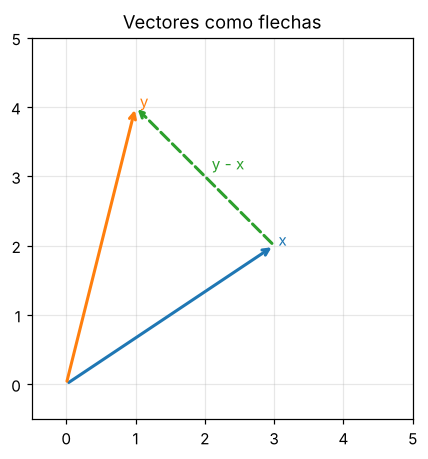

In [2]:
x = np.array([3.0, 2.0])     # un punto (o flecha) en R^2
y = np.array([1.0, 4.0])

print("x.shape =", x.shape, "| x.ndim =", x.ndim)
print("x + y   =", x + y)
print("2 * x   =", 2 * x)
print("y - x   =", y - x, "  <- la flecha que va de x hasta y")

# Una imagen de 3x3 'aplanada' se vuelve un vector de R^9
img = np.arange(9).reshape(3, 3)
print("\nimagen:\n", img)
v = img.flatten()
print("aplanada:", v, "| shape:", v.shape)

# Dibujo de los vectores como flechas
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.annotate("", xy=x, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="tab:blue", lw=2))
ax.annotate("", xy=y, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="tab:orange", lw=2))
ax.annotate("", xy=y, xytext=x, arrowprops=dict(arrowstyle="->", color="tab:green", lw=2, ls="--"))
ax.text(*x, " x", color="tab:blue"); ax.text(*y, " y", color="tab:orange")
ax.text(*((x + y) / 2 + 0.1), "y - x", color="tab:green")
ax.set_xlim(-0.5, 5); ax.set_ylim(-0.5, 5); ax.set_aspect("equal")
ax.set_title("Vectores como flechas")
plt.show()

#### ✏️ Ejercicio 1.1 · Crear un vector

Crea el vector $a=(4,-1,2)$ con `np.array` y comprueba que su forma es `(3,)`.

> ✅ **Resultado esperado:** `a.shape = (3,)` y dos ✅.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
a = np.array(___)

print("a.shape =", a.shape)
verificar("a tiene forma (3,)", a.shape == (3,))
verificar("a = (4, -1, 2)", np.array_equal(a, [4, -1, 2]))

#### ✏️ Ejercicio 1.2 · Combinación lineal

Dados $u=(1,0,2)$ y $v=(0,1,1)$, calcula la combinación lineal $c = 2u - 3v$.

> ✅ **Resultado esperado:** $c=(2,-3,1)$.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
u = np.array([1.0, 0.0, 2.0])
v = np.array([0.0, 1.0, 1.0])

c = ___

print("c =", c)
verificar("c = (2, -3, 1)", np.array_equal(c, [2, -3, 1]))

#### ✏️ Ejercicio 1.3 · Aplanar una imagen

Una imagen de $3\times3$ se aplana para entregársela a una neurona. Aplánala con `.flatten()` y calcula cuántas entradas $n$ tendría una imagen de $28\times28$.

> ✅ **Resultado esperado:** `v.shape = (9,)` y `784`. Tres ✅.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
img = np.arange(9).reshape(3, 3)

v = ___
n_pixeles = ___

print("v.shape =", v.shape, "| n para 28x28 =", n_pixeles)
verificar("v tiene forma (9,)", v.shape == (9,))
verificar("v[4] vale 4 (el pixel del centro)", v[4] == 4)
verificar("28x28 -> 784 entradas", n_pixeles == 784)

---
# Concepto 2 · Producto punto: la suma ponderada

> 🎯 **Objetivo.** Entender que $w^\top x$ es una **suma donde cada entrada cuenta con una importancia distinta**, y calcularla de tres maneras.

## 💡 La idea básica

Piensa en tu nota final de un curso: tiene parcial, taller y proyecto, y cada parte **pesa distinto**. Con notas $x=(4.0,\,3.0,\,5.0)$ y pesos $w=(0.5,\,0.3,\,0.2)$:

$$\text{nota final}=0.5\cdot4.0+0.3\cdot3.0+0.2\cdot5.0=3.9 .$$

Eso es exactamente el **producto punto**:

$$w\cdot x=\sum_{i=1}^{n} w_i\,x_i=w^\top x .$$

Entradas: dos vectores de $\mathbb{R}^n$. Salida: **un solo número**. En una neurona, los pesos $w_i$ son "cuánto le importa a la neurona la entrada $x_i$":

- peso **grande y positivo**: esa entrada empuja el resultado hacia arriba;
- peso **negativo**: la entrada lo empuja hacia abajo;
- peso **cero**: la neurona ignora esa entrada.

El producto punto es **simétrico** ($w\cdot x=x\cdot w$) y **lineal**: $(\alpha w+v)\cdot x=\alpha\,(w\cdot x)+v\cdot x$. Esa linealidad es lo que hace tan manejables a las neuronas.

> 📘 **Definición.** El producto punto se define con la fórmula de arriba. En NumPy: `w @ x` (o `np.dot(w, x)`).

> 🚀 **Para qué sirve después.** Una capa entera de una red es una pila de productos punto; la multiplicación de matrices es "muchos productos punto a la vez". Y un filtro convolucional hace un producto punto en cada parche de la imagen.

## 👀 Ejemplo resuelto (solo ejecútalo)

In [6]:
notas = np.array([4.0, 3.0, 5.0])    # parcial, taller, proyecto
pesos = np.array([0.5, 0.3, 0.2])

# Forma 1: con un ciclo (la definición, paso a paso)
total = 0.0
for xi, wi in zip(notas, pesos):
    total += wi * xi

# Forma 2: con np.dot     Forma 3: con el operador @
print("con ciclo :", total)
print("con np.dot:", np.dot(pesos, notas))
print("con @     :", pesos @ notas)

# Un peso en cero ignora esa entrada: cambia el proyecto y mira qué pasa
w_sin_proyecto = np.array([0.5, 0.3, 0.0])
print("\nignorando el proyecto:", w_sin_proyecto @ notas)
print("cambiando el proyecto a 1.0:", w_sin_proyecto @ np.array([4.0, 3.0, 1.0]), " (igual)")

con ciclo : 3.9
con np.dot: 3.9
con @     : 3.9

ignorando el proyecto: 2.9
cambiando el proyecto a 1.0: 2.9  (igual)


#### ✏️ Ejercicio 2.1 · Producto punto con un ciclo

Calcula $w\cdot x$ **con un ciclo**, acumulando el producto de cada pareja $(x_i,w_i)$. Resultado esperado: $2\cdot1+(-1)\cdot4+3\cdot0.5=-0.5$.

> ✅ **Resultado esperado:** `total = -0.5`.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
x = np.array([2.0, -1.0, 3.0])
w = np.array([1.0, 4.0, 0.5])

total = 0.0
for xi, wi in zip(x, w):
    total += ___

print("total =", total)
verificar("total = -0.5", np.isclose(total, -0.5))

#### ✏️ Ejercicio 2.2 · Sensores de un robot

Un robot lee tres sensores $x=(3.0,\,2.0,\,5.0)$ y los combina con pesos $w=(0.4,\,-0.8,\,0.1)$. Calcula la suma ponderada $s$ con `@` y encuentra **qué entrada tiene el peso que más resta** (usa `np.argmin`; recuerda que Python cuenta desde 0).

> ✅ **Resultado esperado:** $s=0.1$ y el índice `1`.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
x = np.array([3.0, 2.0, 5.0])
w = np.array([0.4, -0.8, 0.1])

s = ___
peso_mas_negativo = ___

print("s =", s, "| índice del peso más negativo =", peso_mas_negativo)
verificar("s = 0.1", np.isclose(s, 0.1))
verificar("el peso más negativo está en la posición 1", peso_mas_negativo == 1)

#### ✏️ Ejercicio 2.3 · Linealidad

Comprueba **numéricamente** la linealidad: calcula el lado izquierdo $(2w+v)\cdot x$ y el derecho $2\,(w\cdot x)+v\cdot x$. Deben coincidir (los dos valen $-6.8$).

> ✅ **Resultado esperado:** Ambos lados valen $-6.8$.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
x = np.array([3.0, 2.0, 5.0])
w = np.array([0.4, -0.8, 0.1])
v = np.array([1.0, 0.0, -2.0])

izq = ___
der = ___

print("izq =", izq, "| der =", der)
verificar("izq = -6.8", np.isclose(izq, -6.8))
verificar("izq y der coinciden", np.isclose(izq, der))

---
# Concepto 3 · Norma, ángulo y ortogonalidad

> 🎯 **Objetivo.** Medir la **longitud** de un vector, el **ángulo** entre dos vectores, y entender que "perpendicular" equivale a "producto punto cero". Esta última idea es la que sostiene todo el concepto del hiperplano.

## 💡 La idea básica

La **norma** (longitud) de un vector es

$$\lVert x\rVert=\sqrt{x\cdot x}=\sqrt{x_1^2+\cdots+x_n^2}.$$

En $\mathbb{R}^2$ es el teorema de Pitágoras: la flecha $(x_1,x_2)$ es la hipotenusa de un triángulo de catetos $x_1$ y $x_2$. Un vector **unitario** tiene norma 1; cualquier $x\neq0$ se vuelve unitario dividiendo: $\hat{x}=\dfrac{x}{\lVert x\rVert}$ (misma dirección, longitud 1).

El producto punto también mide **ángulos**:

$$x\cdot y=\lVert x\rVert\,\lVert y\rVert\cos\theta
\quad\Longrightarrow\quad
\cos\theta=\frac{x\cdot y}{\lVert x\rVert\,\lVert y\rVert}.$$

*(Demostración: ley de cosenos en el triángulo $x$, $y$, $x-y$ y expansión de $(x-y)\cdot(x-y)$; está completa en tu documento "fundamentos". En $\mathbb{R}^n$ con $n>3$ el ángulo se **define** con esta fórmula.)*

Y de ahí sale la idea más importante del cuaderno. Como $\cos90^\circ=0$:

$$\boxed{\,x\perp y\iff x\cdot y=0\,}$$

Una pregunta geométrica ("¿son perpendiculares?") se vuelve una cuenta ("¿el producto punto es cero?").

Por último, la **proyección**: si $u$ es unitario, $u\cdot x$ es la "sombra con signo" de $x$ sobre la dirección de $u$ (positiva si apuntan hacia el mismo lado).

> 🟦 **Teorema.** $x\cdot y=\lVert x\rVert\lVert y\rVert\cos\theta$ y $x\perp y\iff x\cdot y=0$.

> 🚀 **Para qué sirve después.** Sin esto no se entiende el hiperplano ni la distancia de un punto a él, que es lo que mide una neurona. En visión, la similitud de coseno entre vectores de características compara imágenes.

## 👀 Ejemplo resuelto (solo ejecútalo)

In [10]:
x = np.array([3.0, 4.0])
print("norma a mano   :", np.sqrt(x @ x))
print("norma con NumPy:", np.linalg.norm(x), "  (Pitágoras: 3-4-5)")

# Ángulo entre a=(1,0) y b=(1,1): debería ser 45 grados
a = np.array([1.0, 0.0]); b = np.array([1.0, 1.0])
cos_theta = (a @ b) / (np.linalg.norm(a) * np.linalg.norm(b))
print("\ncos(theta) =", cos_theta, "-> theta =", np.degrees(np.arccos(cos_theta)), "grados")

# Perpendiculares: (1,2) y (-2,1)
p = np.array([1.0, 2.0]); q = np.array([-2.0, 1.0])
print("\n(1,2)·(-2,1) =", p @ q, "-> perpendiculares")

# Proyección escalar de x sobre la dirección u=(1,0)
u = np.array([1.0, 0.0])
print("sombra de x=(3,4) sobre el eje horizontal:", u @ x)

norma a mano   : 5.0
norma con NumPy: 5.0   (Pitágoras: 3-4-5)

cos(theta) = 0.7071067811865475 -> theta = 45.00000000000001 grados

(1,2)·(-2,1) = 0.0 -> perpendiculares
sombra de x=(3,4) sobre el eje horizontal: 3.0


#### ✏️ Ejercicio 3.1 · Norma y vector unitario

Calcula la norma de $x=(6,8)$ usando $\sqrt{x\cdot x}$ y obtén el vector unitario $\hat{x}$. La norma de $\hat{x}$ debe ser 1.

> ✅ **Resultado esperado:** `norma = 10.0`, `unitario = [0.6 0.8]`.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
x = np.array([6.0, 8.0])

norma = ___
unitario = ___

print("norma =", norma, "| unitario =", unitario)
verificar("norma = 10", np.isclose(norma, 10))
verificar("el unitario es (0.6, 0.8)", np.allclose(unitario, [0.6, 0.8]))
verificar("la norma del unitario es 1", np.isclose(np.linalg.norm(unitario), 1))

#### ✏️ Ejercicio 3.2 · Ángulo entre dos vectores

Calcula el ángulo en grados entre $u=(2,0)$ y $v=(1,\sqrt3)$. Debe dar $60^\circ$.

> ✅ **Resultado esperado:** $\cos\theta=0.5$ y ángulo $60^\circ$.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
u = np.array([2.0, 0.0])
v = np.array([1.0, np.sqrt(3)])

cos_theta = ___
angulo = np.degrees(np.arccos(cos_theta))

print("cos(theta) =", cos_theta, "| ángulo =", angulo)
verificar("el ángulo es 60 grados", np.isclose(angulo, 60))

#### ✏️ Ejercicio 3.3 · Perpendicular y proyección

Dado $w=(1,2)$: (a) completa las dos coordenadas de un vector $v$ **perpendicular** a $w$ (pista: en $\mathbb{R}^2$ sirve $(-w_2,w_1)$); (b) calcula la **sombra con signo** de $x=(3,2)$ sobre la dirección de $w$, es decir, $x\cdot\hat{w}$ con $\hat w=w/\lVert w\rVert$.

> 💡 **Pista:** Hay muchos $v$ válidos (cualquier múltiplo sirve). El `verificar` comprueba la propiedad, no un valor fijo.

> ✅ **Resultado esperado:** $w\cdot v=0$ y sombra $\approx3.1305$.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
w = np.array([1.0, 2.0])
x = np.array([3.0, 2.0])

v = np.array([___, ___])
sombra = ___

print("w·v =", w @ v, "| sombra =", sombra)
verificar("v es perpendicular a w y no es el vector cero", np.isclose(w @ v, 0) and np.linalg.norm(v) > 0)
verificar("sombra = 7/sqrt(5)", np.isclose(sombra, 7 / np.sqrt(5)))

---
# Concepto 4 · Hiperplano: la "pared" de la neurona

> 🎯 **Objetivo.** Entender que la ecuación $w^\top x+b=0$ describe una **pared plana** (recta en 2D, plano en 3D, hiperplano en $\mathbb{R}^n$), y que $w$ **no es la pared sino la flecha perpendicular a ella**.

## 💡 La idea básica

Empecemos en el plano $\mathbb{R}^2$. Una recta se puede describir con un punto por donde pasa, $p_0$, y una **flecha normal** $n\neq0$ que le es perpendicular. Un punto $x$ está en la recta cuando el desplazamiento $x-p_0$ es perpendicular a $n$ (concepto 3):

$$n\cdot(x-p_0)=0 .$$

Expandimos por linealidad: $n\cdot x-n\cdot p_0=0$. Llamamos $b=-\,n\cdot p_0$ (un número fijo) y queda la forma que verás en todos los libros:

$$n\cdot x+b=0 .$$

La misma receta funciona en $\mathbb{R}^3$ (un **plano**) y en $\mathbb{R}^n$. Usando los nombres de las redes neuronales ($w$ en lugar de $n$):

$$H=\{\,x\in\mathbb{R}^n:\ w^\top x+b=0\,\},\qquad w\neq0 .$$

A $H$ se le llama **hiperplano**. Tiene dimensión $n-1$: una menos que el espacio.

Dos hechos que usaremos todo el tiempo:

1. **$w$ es perpendicular a $H$.** Si $x_1,x_2\in H$, restando sus ecuaciones $w^\top x_1+b=0$ y $w^\top x_2+b=0$ el $b$ se cancela y queda $w^\top(x_1-x_2)=0$. Como $x_1-x_2$ es una dirección **dentro** de la pared, $w$ es perpendicular a todas ellas.
2. **La función $s(x)=w^\top x+b$** vale $0$ sobre la pared, y tiene signos opuestos a los dos lados.

> 🟦 **Teorema.** $w\perp H$ y $\dim H=n-1$ (este último sale del teorema de rango–nulidad).

> ⚠️ **Cuándo deja de valer.** Si $w=0$ no hay pared: la ecuación queda $b=0$, que es siempre falsa o siempre verdadera.

> 🚀 **Para qué sirve después.** Una neurona **es** esa pared con una decisión adicional. Entrenarla es mover la pared hasta separar bien los datos.

## 👀 Ejemplo resuelto (solo ejecútalo)

Tomamos $w=(1,2)$ y $b=-3$, es decir la recta $x_1+2x_2-3=0$.

[1. 1.] -> s = 0.0   <- está SOBRE la recta
[3. 0.] -> s = 0.0   <- está SOBRE la recta
[-1.  2.] -> s = 0.0   <- está SOBRE la recta
[ 5. -1.] -> s = 0.0   <- está SOBRE la recta
[3. 2.] -> s = 4.0 
[0. 0.] -> s = -3.0 


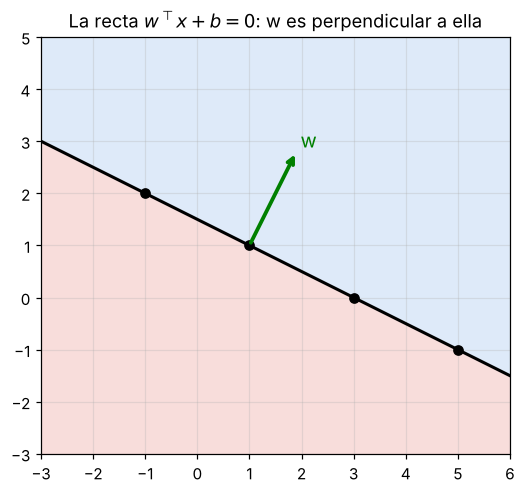

In [14]:
w = np.array([1.0, 2.0])
b = -3.0

def s(x):
    # s(x) = w·x + b
    return x @ w + b

puntos = np.array([[1, 1], [3, 0], [-1, 2], [5, -1], [3, 2], [0, 0]], dtype=float)
for p in puntos:
    marca = "  <- está SOBRE la recta" if np.isclose(s(p), 0) else ""
    print(p, "-> s =", s(p), marca)

# Dibujo: la recta, la flecha w (perpendicular) y los dos lados
g = np.linspace(-3, 6, 300)
X1, X2 = np.meshgrid(g, g)
S = w[0] * X1 + w[1] * X2 + b

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.contourf(X1, X2, np.sign(S), levels=[-2, 0, 2], colors=["#f4c7c3", "#c9dcf5"], alpha=0.6)
d = np.array([-w[1], w[0]])                       # dirección dentro de la recta
p0 = np.array([1.0, 1.0])
L = p0 + np.array([-4, 4])[:, None] * d / np.linalg.norm(d) * 2
ax.plot(L[:, 0], L[:, 1], "k", lw=2)
ax.annotate("", xy=p0 + w * 0.9, xytext=p0, arrowprops=dict(arrowstyle="->", color="green", lw=2.5))
ax.text(*(p0 + w * 0.9 + 0.08), "w", color="green", fontsize=13)
ax.plot(*puntos[:4].T, "ko")
ax.set_xlim(-3, 6); ax.set_ylim(-3, 5); ax.set_aspect("equal")
ax.set_title("La recta $w^\\top x+b=0$: w es perpendicular a ella")
plt.show()

#### ✏️ Ejercicio 4.1 · ¿Qué puntos están en la pared?

Con $w=(2,-1)$ y $b=-4$, decide **cuáles de estos 4 puntos están sobre el hiperplano**. Calcula $s$ para todos a la vez con una sola expresión matricial (`P @ w + b`) y luego usa `np.isclose(..., 0)`.

> ✅ **Resultado esperado:** `s = [ 0.  0.  0. -3.]` y `[True, True, True, False]`.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
w = np.array([2.0, -1.0])
b = -4.0
P = np.array([[2.0, 0.0], [3.0, 2.0], [0.0, -4.0], [1.0, 1.0]])   # (4, 2)

valores = ___
sobre_H = ___

print("s =", valores)
print("sobre H:", sobre_H)
verificar("forma de s = (4,)", valores.shape == (4,))
verificar("los tres primeros están sobre H, el cuarto no", np.array_equal(sobre_H, [True, True, True, False]))

#### ✏️ Ejercicio 4.2 · Del punto y la normal a la ecuación

Construye un hiperplano en $\mathbb{R}^3$ a partir de **un punto y una normal**: $p_0=(2,1,1)$ y $n=(1,2,-3)$. Calcula $b=-\,n\cdot p_0$ y comprueba que el punto $(1,0,0)$ también está en el plano.

> ✅ **Resultado esperado:** $b=-1$ y tres ✅.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
n = np.array([1.0, 2.0, -3.0])
p0 = np.array([2.0, 1.0, 1.0])

b = ___
otro = np.array([1.0, 0.0, 0.0])

print("b =", b, "| s(otro) =", n @ otro + b)
verificar("b = -1", np.isclose(b, -1))
verificar("p0 está en el plano", np.isclose(n @ p0 + b, 0))
verificar("(1,0,0) está en el plano", np.isclose(n @ otro + b, 0))

#### ✏️ Ejercicio 4.3 · w es perpendicular a la pared

Comprueba el teorema "$w\perp H$": toma dos puntos del ejercicio 4.1 que estén sobre $H$, $A=(2,0)$ y $B=(3,2)$. Calcula la dirección $d=B-A$ (una flecha **dentro** de la pared) y verifica que $w\cdot d=0$.

> ✅ **Resultado esperado:** `d = [1. 2.]`, `w·d = 0.0`.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
w = np.array([2.0, -1.0])
A_ = np.array([2.0, 0.0])
B_ = np.array([3.0, 2.0])

d = ___
producto = ___

print("d =", d, "| w·d =", producto)
verificar("d = (1, 2)", np.array_equal(d, [1, 2]))
verificar("w es perpendicular a la pared", np.isclose(producto, 0))

---
# Concepto 5 · Distancia con signo y semiespacios

> 🎯 **Objetivo.** Saber **de qué lado** de la pared está un punto y **a qué distancia**, y ver que $s=w^\top x+b$ no es la distancia pura sino la distancia multiplicada por $\lVert w\rVert$.

## 💡 La idea básica

La pared divide el espacio en dos mitades (**semiespacios**):

- $s(x)>0$: el lado hacia el que apunta $w$,
- $s(x)<0$: el lado contrario,
- $s(x)=0$: justo sobre la pared.

Pero hay más información: el *valor* de $s$ dice qué tan lejos. Para verlo, descomponemos $x$ en su punto más cercano de la pared, $x_p\in H$, más un desplazamiento a lo largo de la normal unitaria $\hat{w}=w/\lVert w\rVert$:

$$x=x_p+t\,\hat{w}.$$

Aquí $|t|$ es la distancia y el signo de $t$ dice el lado. Sustituimos en $s$:

$$s(x)=\underbrace{w^\top x_p+b}_{=0}+t\,w^\top\hat{w}=t\,\frac{w^\top w}{\lVert w\rVert}=t\,\lVert w\rVert .$$

Despejando:

$$\boxed{\,t=\frac{w^\top x+b}{\lVert w\rVert}\,}$$

y el punto más cercano de la pared es $x_p=x-t\,\hat{w}$.

Por tanto **$s=\lVert w\rVert\cdot t$**: la neurona entrega la distancia con signo *escalada* por la longitud de $w$.

> 🟦 **Teorema.** La distancia con signo de $x$ a $H$ es $t=\dfrac{w^\top x+b}{\lVert w\rVert}$.

> 🚀 **Para qué sirve después.** Es el significado geométrico de lo que calcula una neurona: "¿de qué lado y qué tan lejos de mi pared estás?". Los clasificadores tipo SVM maximizan justamente esta distancia.

## 👀 Ejemplo resuelto (solo ejecútalo)

s(x)          = 4.0
||w||         = 2.23606797749979
t = s/||w||   = 1.7888543819998317
punto x_p     = [2.2 0.4] -> s(x_p) = 4.440892098500626e-16 (está en la pared)
|x - x_p|     = 1.7888543819998315 (coincide con |t|)


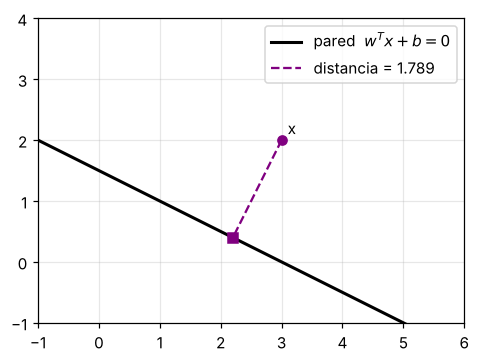

In [18]:
w = np.array([1.0, 2.0]); b = -3.0
x = np.array([3.0, 2.0])

s_x = w @ x + b
t = s_x / np.linalg.norm(w)                  # distancia con signo
x_p = x - t * w / np.linalg.norm(w)          # punto más cercano de la pared

print("s(x)          =", s_x)
print("||w||         =", np.linalg.norm(w))
print("t = s/||w||   =", t)
print("punto x_p     =", x_p, "-> s(x_p) =", w @ x_p + b, "(está en la pared)")
print("|x - x_p|     =", np.linalg.norm(x - x_p), "(coincide con |t|)")

fig, ax = plt.subplots(figsize=(5, 5))
g = np.linspace(-1, 6, 5)
ax.plot(g, (3 - g) / 2, "k", lw=2, label="pared  $w^T x+b=0$")
ax.plot(*x, "o", color="purple"); ax.text(x[0] + .1, x[1] + .1, "x")
ax.plot(*x_p, "s", color="purple")
ax.plot([x[0], x_p[0]], [x[1], x_p[1]], "--", color="purple", label=f"distancia = {abs(t):.3f}")
ax.set_xlim(-1, 6); ax.set_ylim(-1, 4); ax.set_aspect("equal"); ax.legend(loc="upper right")
plt.show()

#### ✏️ Ejercicio 5.1 · Distancia con signo

Con $w=(3,4)$, $b=-10$ y el punto $x=(0,0)$, calcula la **distancia con signo** $t$. Interpreta el resultado: ¿de qué lado está el origen?

> ✅ **Resultado esperado:** $t=-2$ (lado negativo, a 2 unidades de la pared).

In [ ]:
# ✏️ Rellena los ___ y ejecuta
w = np.array([3.0, 4.0])
b = -10.0
x = np.array([0.0, 0.0])

t = ___

print("t =", t)
verificar("t = -2", np.isclose(t, -2))
verificar("el origen queda en el lado negativo", t < 0)

#### ✏️ Ejercicio 5.2 · ¿De qué lado está cada punto?

Con $w=(1,-1)$ y $b=0$, clasifica estos 5 puntos por lado usando `np.sign`: $+1$ (lado positivo), $-1$ (negativo) o $0$ (sobre la pared). Calcula todo de una vez con la forma matricial.

> ✅ **Resultado esperado:** `[ 1. -1.  0.  0.  1.]`.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
w = np.array([1.0, -1.0])
b = 0.0
X = np.array([[2.0, 1.0], [1.0, 3.0], [4.0, 4.0], [0.0, 0.0], [5.0, -1.0]])   # (5, 2)

lados = ___

print("lados =", lados)
verificar("lados = [1, -1, 0, 0, 1]", np.array_equal(lados, [1, -1, 0, 0, 1]))

#### ✏️ Ejercicio 5.3 · El punto más cercano de la pared

Con $w=(3,4)$, $b=-10$ y $x=(5,5)$: calcula $t$ y el **punto más cercano de la pared** $x_p=x-t\,\hat w$. Comprueba que $x_p$ está en la pared y que $\lVert x-x_p\rVert=|t|$.

> ✅ **Resultado esperado:** $t=5$, $x_p=(2,1)$ y tres ✅.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
w = np.array([3.0, 4.0])
b = -10.0
x = np.array([5.0, 5.0])

t = (w @ x + b) / np.linalg.norm(w)
x_p = ___

print("t =", t, "| x_p =", x_p)
verificar("x_p está sobre la pared", np.isclose(w @ x_p + b, 0))
verificar("|x - x_p| = |t|", np.isclose(np.linalg.norm(x - x_p), abs(t)))
verificar("x_p = (2, 1)", np.allclose(x_p, [2, 1]))

---
# Concepto 6 · El sesgo $b$

> 🎯 **Objetivo.** Entender qué mueve $b$ y por qué **sin él la neurona sería demasiado limitada**.

## 💡 La idea básica

Si $w$ fija **hacia dónde está orientada** la pared, $b$ fija **dónde está colocada**. Evaluemos en el origen: $s(0)=b$. Por la fórmula del concepto 5, la distancia con signo del origen a la pared es $b/\lVert w\rVert$; sin signo:

$$\text{distancia de } H \text{ al origen}=\frac{|b|}{\lVert w\rVert}.$$

Cambiar $b$ **traslada** la pared a lo largo de $w$ sin girarla (la normal sigue siendo $w$). Por eso las rectas $w^\top x+b=c$ para distintos $c$ son **paralelas**: son todas la misma pared desplazada.

¿Por qué hace falta? Si $b=0$, la pared **pasa siempre por el origen**. Y eso impide cosas simples. Ejemplo: dos puntos $A=(1,1)$ de la clase 0 y $B=(3,3)$ de la clase 1. Como $B=3A$, con $b=0$ se cumple $s(B)=3\,s(A)$: **siempre tienen el mismo signo**, y ninguna pared por el origen puede separarlos. Con un sesgo adecuado sí se puede.

> 🟦 **Teorema.** Con $b=0$ el hiperplano contiene al origen; con $b\ne0$ está a distancia $|b|/\lVert w\rVert$ de él.

> 🚀 **Para qué sirve después.** En redes grandes cada neurona tiene su propio $b$. Muchas veces se interpreta como el "umbral": qué tan fácil es que la neurona se active independientemente de las entradas.

## 👀 Ejemplo resuelto (solo ejecútalo)

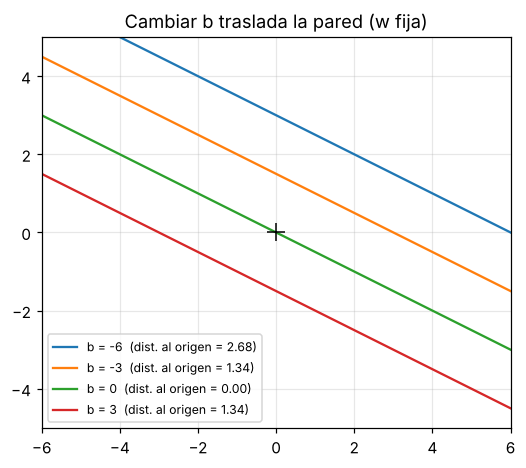

separaciones logradas SIN sesgo: 0 de 20000
separaciones logradas CON sesgo: 1500 de 20000


In [22]:
w = np.array([1.0, 2.0])

# Misma w, distintos b: paredes paralelas
fig, ax = plt.subplots(figsize=(5.5, 5.5))
g = np.linspace(-6, 6, 100)
for b in (-6, -3, 0, 3):
    ax.plot(g, -(w[0] * g + b) / w[1], label=f"b = {b}  (dist. al origen = {abs(b) / np.linalg.norm(w):.2f})")
ax.plot(0, 0, "k+", ms=12)
ax.set_xlim(-6, 6); ax.set_ylim(-5, 5); ax.set_aspect("equal"); ax.legend(fontsize=8)
ax.set_title("Cambiar b traslada la pared (w fija)")
plt.show()

# Sin sesgo no se pueden separar A=(1,1) [clase 0] y B=(3,3) [clase 1]
rng = np.random.default_rng(0)
A_pt = np.array([1.0, 1.0]); B_pt = np.array([3.0, 3.0])
ws = rng.normal(size=(20000, 2))                # 20000 vectores w al azar

sin_b = (ws @ A_pt < 0) & (ws @ B_pt > 0)       # s(A)<0 y s(B)>0 con b=0
bs = rng.normal(scale=4, size=20000)            # 20000 sesgos al azar
con_b = (ws @ A_pt + bs < 0) & (ws @ B_pt + bs > 0)

print("separaciones logradas SIN sesgo:", sin_b.sum(), "de 20000")
print("separaciones logradas CON sesgo:", con_b.sum(), "de 20000")

#### ✏️ Ejercicio 6.1 · Distancia de la pared al origen

Calcula la distancia de la pared al origen para $w=(3,4)$ y $b=10$.

> ✅ **Resultado esperado:** `2.0`.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
w = np.array([3.0, 4.0])
b = 10.0

dist_origen = ___

print("distancia al origen =", dist_origen)
verificar("distancia = 2", np.isclose(dist_origen, 2))

#### ✏️ Ejercicio 6.2 · Elegir b para pasar por un punto

Con $w=(1,-1)$, ¿qué valor de $b$ hace que la pared **pase por el punto $p=(2,3)$**? Despeja de $w\cdot p+b=0$.

> ✅ **Resultado esperado:** $b=1$.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
w = np.array([1.0, -1.0])
p = np.array([2.0, 3.0])

b = ___

print("b =", b)
verificar("la pared pasa por p", np.isclose(w @ p + b, 0))
verificar("b = 1", np.isclose(b, 1))

#### ✏️ Ejercicio 6.3 · Separar dos puntos con sesgo

**Separa lo que sin sesgo era imposible.** Elige $w$ y $b$ con $b\neq0$ de modo que $A=(1,1)$ quede en el lado negativo ($s<0$) y $B=(3,3)$ en el positivo ($s>0$).

> 💡 **Pista:** Piensa en una pared que pase *entre* los dos puntos, es decir, a medio camino: por ejemplo por $(2,2)$.

> ✅ **Resultado esperado:** Con $w=(1,1)$ y $b=-4$: $s(A)=-2$, $s(B)=2$.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
A_pt = np.array([1.0, 1.0])
B_pt = np.array([3.0, 3.0])

w = np.array([___, ___])
b = ___

sA = w @ A_pt + b
sB = w @ B_pt + b
print("s(A) =", sA, "| s(B) =", sB)
verificar("A queda en el lado negativo", sA < 0)
verificar("B queda en el lado positivo", sB > 0)
verificar("usaste un sesgo distinto de cero", b != 0)

---
# Concepto 7 · Función de activación

> 🎯 **Objetivo.** Entender qué hace $f$ con el número $s=w^\top x+b$, y por qué **sin una $f$ no lineal** apilar neuronas no sirve de nada.

## 💡 La idea básica

La neurona biológica no repite todo lo que oye: suma las señales y **dispara solo si el total es suficiente**. En la neurona artificial, ese "disparar o no" lo hace la función de activación $f:\mathbb{R}\to\mathbb{R}$, que se aplica a $s$:

$$z=f(s)=f\!\left(w^\top x+b\right).$$

Cuatro activaciones clásicas:

| Nombre | Fórmula | Qué hace |
|---|---|---|
| Escalón | $f(s)=\begin{cases}1&s\ge0\\0&s<0\end{cases}$ | Decide sí/no; pero no es derivable donde salta |
| Sigmoide | $\sigma(s)=\dfrac{1}{1+e^{-s}}$ | Aplasta $\mathbb{R}$ en $(0,1)$; se lee como probabilidad |
| ReLU | $\max(0,s)$ | Deja pasar lo positivo, corta lo negativo |
| Tanh | $\tanh(s)$ | Como la sigmoide pero en $(-1,1)$ |

**¿Por qué no basta con $s$?** Porque una función afín seguida de otra función afín es **otra función afín**. Si $g_1(x)=a_1x+c_1$ y $g_2(x)=a_2x+c_2$, entonces

$$g_2\big(g_1(x)\big)=a_2(a_1x+c_1)+c_2=(a_2a_1)\,x+(a_2c_1+c_2),$$

que sigue siendo de la forma $Ax+C$. Mil capas sin activación equivalen a una sola. La no linealidad de $f$ es lo que permite que una red represente cosas complicadas.

Conexión con la geometría: con el escalón o la sigmoide, "$z\ge0.5$" equivale a "$s\ge0$", o sea, **de qué lado de la pared estás**. La activación convierte la distancia con signo en una decisión.

> 🟦 **Teorema.** La composición de funciones afines es afín (el cálculo de arriba).
> 🟦 **Teorema (aproximación universal).** Redes con una capa oculta y activación no polinómica adecuada pueden aproximar funciones continuas sobre compactos tan bien como se quiera. Dice que *existe* una red; **no** dice cuántas neuronas hacen falta ni cómo encontrarla.
> 🟧 **Práctica empírica.** Usar ReLU por defecto en capas ocultas funciona bien y es barato de calcular, pero no está demostrado que sea la mejor.

> 🚀 **Para qué sirve después.** Elegir la activación de la última capa define el tipo de problema: sigmoide para "sí/no", otras para varias clases o valores continuos.

## 👀 Ejemplo resuelto (solo ejecútalo)

s        : [-3.  -1.   0.   0.3  1.   3. ]
escalón  : [0. 0. 1. 1. 1. 1.]
sigmoide : [0.0474 0.2689 0.5    0.5744 0.7311 0.9526]
ReLU     : [0.  0.  0.  0.3 1.  3. ]
tanh     : [-0.9951 -0.7616  0.      0.2913  0.7616  0.9951]


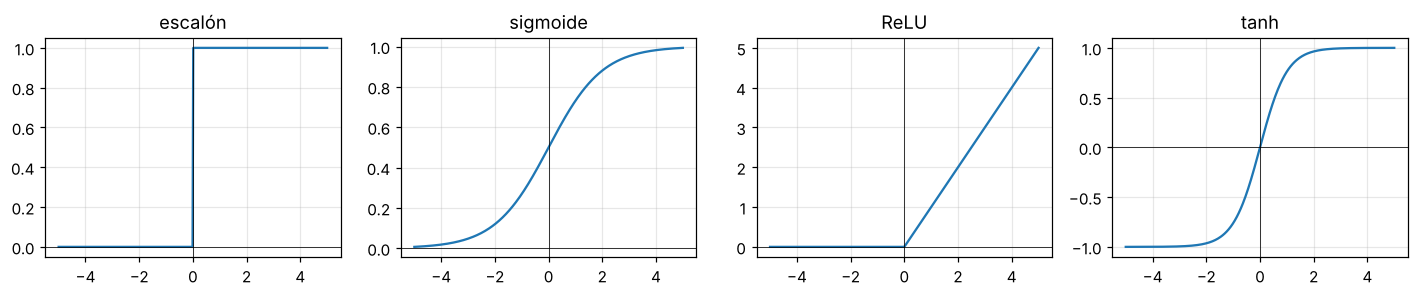


g2(g1(x))   : [ 13.   7.   1.  -5. -11.]
-6x + 1     : [ 13.   7.   1.  -5. -11.]  (idéntico: colapsó)
g2(relu(g1)): [  4.   4.   1.  -5. -11.]  (ya NO es una recta)


In [26]:
def escalon(s):   return np.where(s >= 0, 1.0, 0.0)
def sigmoide(s):  return 1 / (1 + np.exp(-s))
def relu(s):      return np.maximum(0, s)

s_vals = np.array([-3.0, -1.0, 0.0, 0.3, 1.0, 3.0])
print("s        :", s_vals)
print("escalón  :", escalon(s_vals))
print("sigmoide :", sigmoide(s_vals))
print("ReLU     :", relu(s_vals))
print("tanh     :", np.tanh(s_vals))

g = np.linspace(-5, 5, 400)
fig, axs = plt.subplots(1, 4, figsize=(13, 2.8), sharex=True)
for ax, (nombre, f) in zip(axs, [("escalón", escalon), ("sigmoide", sigmoide), ("ReLU", relu), ("tanh", np.tanh)]):
    ax.plot(g, f(g)); ax.set_title(nombre); ax.axhline(0, color="k", lw=.5); ax.axvline(0, color="k", lw=.5)
plt.tight_layout(); plt.show()

# Dos capas afines SIN activación colapsan en una sola:
g1 = lambda x: 2 * x + 1
g2 = lambda x: -3 * x + 4
xs = np.linspace(-2, 2, 5)
print("\ng2(g1(x))   :", g2(g1(xs)))
print("-6x + 1     :", -6 * xs + 1, " (idéntico: colapsó)")
print("g2(relu(g1)):", g2(relu(g1(xs))), " (ya NO es una recta)")

#### ✏️ Ejercicio 7.1 · Sigmoide

Implementa la **sigmoide** $\sigma(s)=\dfrac{1}{1+e^{-s}}$ con `np.exp`.

> ✅ **Resultado esperado:** `0.5 0.8808 [0.2689 0.7311]` y tres ✅.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
def mi_sigmoide(s):
    return ___

print(mi_sigmoide(0.0), mi_sigmoide(2.0), mi_sigmoide(np.array([-1.0, 1.0])))
verificar("sigma(0) = 0.5", np.isclose(mi_sigmoide(0.0), 0.5))
verificar("sigma(2) = 0.8808", np.isclose(mi_sigmoide(2.0), 0.8808, atol=1e-4))
verificar("simetría: sigma(-s) = 1 - sigma(s)", np.isclose(mi_sigmoide(-1.7), 1 - mi_sigmoide(1.7)))

#### ✏️ Ejercicio 7.2 · ReLU y escalón

Implementa **ReLU** con `np.maximum` y el **escalón** con `np.where`. Pruébalas con $s=(-2,0,3)$.

> ✅ **Resultado esperado:** `[0. 0. 3.]` y `[0. 1. 1.]`.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
def mi_relu(s):
    return ___

def mi_escalon(s):
    return ___

s = np.array([-2.0, 0.0, 3.0])
print("ReLU   :", mi_relu(s))
print("escalón:", mi_escalon(s))
verificar("ReLU = [0, 0, 3]", np.array_equal(mi_relu(s), [0, 0, 3]))
verificar("escalón = [0, 1, 1]", np.array_equal(mi_escalon(s), [0, 1, 1]))

#### ✏️ Ejercicio 7.3 · Dos capas lineales colapsan

**Colapso afín.** Sean $g_1(x)=2x+1$ y $g_2(x)=-3x+4$. Sin hacer la composición numérica, deduce a mano los coeficientes $A$ y $C$ tales que $g_2(g_1(x))=Ax+C$, y comprueba que coinciden en varios puntos.

> 💡 **Pista:** $g_2(g_1(x))=-3(2x+1)+4$. Distribuye el $-3$.

> ✅ **Resultado esperado:** Con $A=-6$, $C=1$ ambas líneas son idénticas.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
g1 = lambda x: 2 * x + 1
g2 = lambda x: -3 * x + 4

A_coef = ___
C_coef = ___

xs = np.linspace(-2, 2, 5)
print("g2(g1(x)) :", g2(g1(xs)))
print("A x + C   :", A_coef * xs + C_coef)
verificar("coinciden en todos los puntos", np.allclose(g2(g1(xs)), A_coef * xs + C_coef))

---
# Concepto 8 · Lotes y forma matricial

> 🎯 **Objetivo.** Calcular la salida de la neurona para **muchos datos a la vez**, controlando las formas de los arreglos y entendiendo por qué se escribe así.

## 💡 La idea básica

Hasta ahora procesamos un dato a la vez. En la práctica se procesan **lotes** (*batches*). Apilamos $N$ datos como filas de una matriz $X\in\mathbb{R}^{N\times n}$ ($N$ filas, $n$ columnas). La fila $i$ es el dato $x^{(i)}$. Entonces:

$$s=Xw+b\mathbf{1}\in\mathbb{R}^{N},\qquad s_i=x^{(i)\top}w+b .$$

Cada entrada de $Xw$ es el producto punto de **una fila de $X$** con $w$. En NumPy escribimos `X @ w + b` y el escalar $b$ se **replica** solo (*broadcasting*).

Reglas de forma que conviene tener siempre presentes:

| Operación | Formas | Resultado |
|---|---|---|
| `X @ w` | $(N,n)\cdot(n,)$ | $(N,)$ |
| `X @ W.T` | $(N,n)\cdot(n,m)$ | $(N,m)$ |
| `A + b` con $b$ de forma $(m,)$ | $(N,m)+(m,)$ | $(N,m)$ (se suma $b$ a cada fila) |

El caso $(N,n)\cdot(n,m)$ es una **capa de $m$ neuronas**: $Y=XW^\top+\mathbf{1}b^\top$ con $W\in\mathbb{R}^{m\times n}$ (cada fila de $W$ es una neurona). Es lo que viste en la Semana 1.

¿Por qué se vectoriza? Porque un ciclo de Python por cada dato es **muchísimo más lento** que una multiplicación de matrices que corre en código compilado optimizado. Lo veremos medido.

> 🟦 **Teorema/hecho.** `X @ w` calcula el producto punto de cada fila con $w$ (es la definición de producto matricial).
> 🟧 **Práctica.** Vectorizar en lugar de usar ciclos: es la regla en computación numérica.

> 🚀 **Para qué sirve después.** Entrenar con GPU depende de esto: miles de datos y miles de neuronas se calculan con una sola multiplicación de matrices.

## 👀 Ejemplo resuelto (solo ejecútalo)

In [30]:
import time

w = np.array([1.0, 2.0]); b = -3.0
X = np.array([[1.0, 1.0], [3.0, 0.0], [3.0, 2.0], [0.0, 0.0]])    # (4, 2): 4 datos

s_lote = X @ w + b
print("X.shape =", X.shape, "| w.shape =", w.shape, "| s.shape =", s_lote.shape)
print("s con matrices:", s_lote)
print("s con ciclo   :", np.array([x @ w + b for x in X]))

# Velocidad: 200 000 datos con 10 entradas
rng = np.random.default_rng(0)
N, n = 200_000, 10
XX = rng.normal(size=(N, n)); ww = rng.normal(size=n)

t0 = time.perf_counter()
s_ciclo = np.array([XX[i] @ ww + 0.5 for i in range(N)])
t_ciclo = time.perf_counter() - t0

t0 = time.perf_counter()
s_mat = XX @ ww + 0.5
t_mat = time.perf_counter() - t0

print(f"\nciclo: {t_ciclo:.4f} s | matricial: {t_mat:.4f} s | el ciclo tarda ~{t_ciclo / t_mat:.0f} veces más")
print("¿mismo resultado?", np.allclose(s_ciclo, s_mat))

X.shape = (4, 2) | w.shape = (2,) | s.shape = (4,)
s con matrices: [ 0.  0.  4. -3.]
s con ciclo   : [ 0.  0.  4. -3.]



ciclo: 0.1810 s | matricial: 0.0028 s | el ciclo tarda ~64 veces más
¿mismo resultado? True


#### ✏️ Ejercicio 8.1 · Un lote con una sola expresión

Calcula $s=Xw+b$ para un lote de 5 datos con 3 entradas cada uno, con **una sola expresión**. Debe tener forma $(5,)$.

> ✅ **Resultado esperado:** `[ 0.5  6.5 12.5 18.5 24.5]`.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
X = np.arange(15, dtype=float).reshape(5, 3)
w = np.array([1.0, 2.0, -1.0])
b = 0.5

s = ___

print("s =", s, "| forma:", s.shape)
verificar("forma (5,)", s.shape == (5,))
verificar("s = [0.5, 6.5, 12.5, 18.5, 24.5]", np.allclose(s, [0.5, 6.5, 12.5, 18.5, 24.5]))

#### ✏️ Ejercicio 8.2 · Una neurona como capa de 1 neurona

Una neurona también se puede ver como una **capa de 1 neurona**. Convierte $w$ (forma $(3,)$) en una matriz $W$ de forma $(1,3)$ con `reshape` y calcula $S=XW^\top+b$. Debe dar forma $(5,1)$ y los mismos valores que antes.

> ✅ **Resultado esperado:** `W.shape = (1, 3)`, `S.shape = (5, 1)` y tres ✅.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
X = np.arange(15, dtype=float).reshape(5, 3)
w = np.array([1.0, 2.0, -1.0])
b = 0.5

W = ___
S = ___

print("W.shape =", W.shape, "| S.shape =", S.shape)
verificar("W tiene forma (1, 3)", W.shape == (1, 3))
verificar("S tiene forma (5, 1)", S.shape == (5, 1))
verificar("S coincide con X@w+b", np.allclose(S[:, 0], X @ w + b))

#### ✏️ Ejercicio 8.3 · Una capa de 3 neuronas

**Una capa de 3 neuronas.** Con $X\in\mathbb{R}^{6\times4}$, $W\in\mathbb{R}^{3\times4}$ y $b\in\mathbb{R}^3$, calcula $Y=XW^\top+b$. Debe tener forma $(6,3)$, y `Y[2, 1]` debe ser la salida de la neurona 1 para el dato 2.

> 💡 **Pista:** El broadcasting suma $b$ (forma $(3,)$) a cada fila de $XW^\top$ (forma $(6,3)$).

> ✅ **Resultado esperado:** `Y.shape = (6, 3)` y dos ✅.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
rng = np.random.default_rng(1)
X = rng.normal(size=(6, 4))
W = rng.normal(size=(3, 4))
b = np.array([0.1, -0.2, 0.3])

Y = ___

print("Y.shape =", Y.shape)
verificar("forma (6, 3)", Y.shape == (6, 3))
verificar("Y[2,1] = X[2]·W[1] + b[1]", np.isclose(Y[2, 1], X[2] @ W[1] + b[1]))

---
# Concepto 9 · Función de pérdida

> 🎯 **Objetivo.** Tener **un número** que diga qué tan mal lo está haciendo la neurona. Sin él no hay manera de decidir cómo mejorar.

## 💡 La idea básica

Para ajustar $w$ y $b$ hace falta una medida del error. Si tenemos las etiquetas verdaderas $y_i$ y las salidas $z_i$ de la neurona, una **función de pérdida** resume todo el error en un solo número que queremos **hacer pequeño**.

**Error cuadrático medio (MSE)**, natural para valores continuos:

$$L_{\text{MSE}}=\frac{1}{N}\sum_{i=1}^{N}(z_i-y_i)^2 .$$

**Entropía cruzada binaria (BCE)**, la estándar para clasificar en dos clases cuando $z_i=\sigma(s_i)\in(0,1)$ se lee como "probabilidad de la clase 1":

$$L_{\text{BCE}}=-\frac{1}{N}\sum_{i=1}^{N}\Big[\,y_i\ln z_i+(1-y_i)\ln(1-z_i)\Big],\qquad y_i\in\{0,1\}.$$

Mírala con calma. Si $y_i=1$, solo cuenta $-\ln z_i$: vale $0$ cuando $z_i=1$ y **crece sin límite** cuando $z_i\to0$. Es decir: equivocarse con mucha seguridad se castiga muchísimo. Si $y_i=0$, solo cuenta $-\ln(1-z_i)$, y es simétrico.

Detalle práctico: $\ln 0=-\infty$, así que se recorta $z$ a $[\varepsilon,1-\varepsilon]$ (por ejemplo $\varepsilon=10^{-12}$) antes de calcular el logaritmo.

> 📘 **Definición.** Ambas pérdidas se definen así. La BCE es la log-verosimilitud negativa de un modelo de Bernoulli, lo que justifica usarla para clasificar (resultado de estadística, con sus supuestos: datos independientes y modelo correcto).
> 🟧 **Práctica empírica.** BCE con sigmoide suele entrenar mejor que MSE para clasificar; MSE con sigmoide puede aprender lento por saturación.

> 🚀 **Para qué sirve después.** Toda la clasificación en visión por computador (¿qué objeto es?, ¿hay obstáculo?) minimiza una variante de esta pérdida.

## 👀 Ejemplo resuelto (solo ejecútalo)

MSE = 0.1025
BCE = 0.31119869971179775
y=1, la neurona dice z=0.99  -> pérdida = 0.010
y=1, la neurona dice z=0.5   -> pérdida = 0.693
y=1, la neurona dice z=0.1   -> pérdida = 2.303
y=1, la neurona dice z=0.01  -> pérdida = 4.605


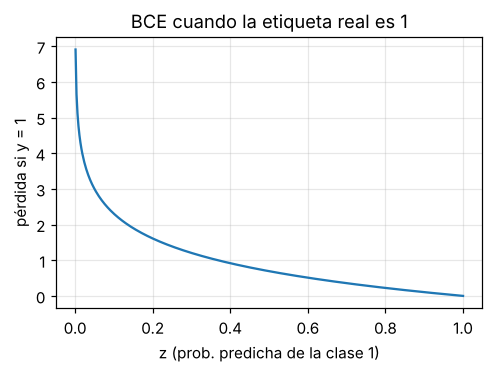

In [34]:
y_real = np.array([1.0, 0.0, 1.0, 1.0])
z_pred = np.array([0.9, 0.2, 0.4, 1.0])

mse = np.mean((z_pred - y_real) ** 2)
print("MSE =", mse)

def bce_ejemplo(y, z, eps=1e-12):
    z = np.clip(z, eps, 1 - eps)
    return -np.mean(y * np.log(z) + (1 - y) * np.log(1 - z))

print("BCE =", bce_ejemplo(y_real, z_pred))

# Castigo según la seguridad con que se equivoca (la etiqueta real es y=1)
for p in (0.99, 0.5, 0.1, 0.01):
    print(f"y=1, la neurona dice z={p:<5} -> pérdida = {-np.log(p):.3f}")

g = np.linspace(0.001, 1, 400)
plt.figure(figsize=(5, 3.2))
plt.plot(g, -np.log(g)); plt.xlabel("z (prob. predicha de la clase 1)"); plt.ylabel("pérdida si y = 1")
plt.title("BCE cuando la etiqueta real es 1"); plt.show()

#### ✏️ Ejercicio 9.1 · Error cuadrático medio

Calcula el **MSE** entre $y=(1,0,1,1)$ y $z=(0.9,0.2,0.4,1.0)$. Resultado esperado: $\frac{0.01+0.04+0.36+0}{4}=0.1025$.

> ✅ **Resultado esperado:** `MSE = 0.1025`.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
y = np.array([1.0, 0.0, 1.0, 1.0])
z = np.array([0.9, 0.2, 0.4, 1.0])

mse = ___

print("MSE =", mse)
verificar("MSE = 0.1025", np.isclose(mse, 0.1025))

#### ✏️ Ejercicio 9.2 · Entropía cruzada binaria

Implementa la **entropía cruzada binaria** promediada. Pruébala con $y=(1,0,1)$ y $z=(0.9,0.2,0.6)$.

> ✅ **Resultado esperado:** `BCE = 0.2797...` y dos ✅.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
def mi_bce(y, z, eps=1e-12):
    z = np.clip(z, eps, 1 - eps)
    return -np.mean(___)

y = np.array([1.0, 0.0, 1.0])
z = np.array([0.9, 0.2, 0.6])
L = mi_bce(y, z)

print("BCE =", L)
verificar("BCE = 0.2798", np.isclose(L, 0.2798, atol=1e-4))
verificar("si la neurona acierta con seguridad, la pérdida es ~0", mi_bce(np.array([1.0]), np.array([1.0])) < 1e-9)

#### ✏️ Ejercicio 9.3 · Equivocarse con seguridad cuesta caro

**Observa el castigo.** Para $y=1$, calcula $-\ln z$ con $z\in(0.99,\,0.5,\,0.1,\,0.01)$. Verifica que la pérdida **crece** cuando la neurona se equivoca con más seguridad.

> ✅ **Resultado esperado:** `[0.01   0.6931 2.3026 4.6052]`.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
p = np.array([0.99, 0.5, 0.1, 0.01])

perdidas = ___

print("pérdidas =", perdidas)
verificar("la pérdida crece estrictamente", np.all(np.diff(perdidas) > 0))
verificar("con z=0.01 la pérdida es ~4.605", np.isclose(perdidas[-1], 4.605, atol=1e-3))

---
# Concepto 10 · Gradiente y descenso de gradiente

> 🎯 **Objetivo.** Entender **cómo se ajustan $w$ y $b$ para reducir la pérdida**, deducir el gradiente de la neurona con sigmoide y BCE, y **verificarlo con diferencias finitas**.

## 💡 La idea básica

La pérdida $L(w,b)$ es una función de los parámetros. Imagina que es un paisaje montañoso y estamos parados en algún punto. Queremos bajar. El **gradiente** $\nabla L$ (el vector de derivadas parciales) apunta hacia donde la pérdida **sube más rápido**; por tanto, para bajar damos un paso en la dirección **contraria**:

$$w\leftarrow w-\eta\,\nabla_w L,\qquad b\leftarrow b-\eta\,\frac{\partial L}{\partial b}.$$

El número $\eta>0$ es la **tasa de aprendizaje**: el tamaño del paso. Muy pequeña: tarda una eternidad. Muy grande: se pasa de largo y puede divergir.

**Derivación para una neurona con sigmoide y BCE** (un solo dato, $y\in\{0,1\}$). Con $s=w^\top x+b$ y $z=\sigma(s)$:

$$L=-\big[y\ln z+(1-y)\ln(1-z)\big].$$

Regla de la cadena: $\dfrac{\partial L}{\partial s}=\dfrac{\partial L}{\partial z}\cdot\dfrac{\partial z}{\partial s}$. Calculamos cada factor.

Primero, la derivada respecto a $z$:

$$\frac{\partial L}{\partial z}=-\frac{y}{z}+\frac{1-y}{1-z}.$$

Segundo, la derivada de la sigmoide (se puede comprobar derivando $\sigma(s)=(1+e^{-s})^{-1}$): $\dfrac{\partial z}{\partial s}=z(1-z)$. Multiplicamos:

$$\frac{\partial L}{\partial s}=\Big(-\frac{y}{z}+\frac{1-y}{1-z}\Big)z(1-z)=-y(1-z)+(1-y)z=-y+yz+z-yz=z-y .$$

Todo se simplifica a **$z-y$**: el error de la predicción. Como $\dfrac{\partial s}{\partial w_i}=x_i$ y $\dfrac{\partial s}{\partial b}=1$:

$$\boxed{\,\nabla_w L=(z-y)\,x,\qquad \frac{\partial L}{\partial b}=z-y\,}$$

Para un lote de $N$ datos (promediando), con $X\in\mathbb{R}^{N\times n}$ y $z,y\in\mathbb{R}^{N}$:

$$\nabla_w L=\frac{1}{N}X^{\top}(z-y)\in\mathbb{R}^{n},\qquad \frac{\partial L}{\partial b}=\frac{1}{N}\sum_i (z_i-y_i).$$

**Siempre se comprueba un gradiente con diferencias finitas.** La derivada numérica centrada es

$$\frac{\partial L}{\partial w_i}\approx\frac{L(w+h\,e_i)-L(w-h\,e_i)}{2h},\qquad h\sim10^{-6},$$

donde $e_i$ es el vector con un 1 en la posición $i$. Si coincide con tu fórmula, la derivación y el código están bien.

> 🟦 **Teorema.** El gradiente apunta en la dirección de máximo crecimiento local, y para esta neurona $\nabla_wL=(z-y)x$ (la derivación de arriba).
> ⚠️ **Cuándo deja de valer.** El descenso de gradiente encuentra mínimos **locales**. Para esta neurona (regresión logística) la pérdida BCE es convexa, así que el mínimo es global; en redes profundas **no hay esa garantía**.
> 🟨 **Heurística.** Valores típicos de $\eta$ ($0.1$, $0.01$, $0.001$) son punto de partida, no una regla.

> 🚀 **Para qué sirve después.** La retropropagación (*backpropagation*) es esta misma regla de la cadena aplicada capa por capa.

## 👀 Ejemplo resuelto (solo ejecútalo)

Primero, el descenso en el caso más simple: $f(w)=(w-3)^2$, con derivada $f'(w)=2(w-3)$ y mínimo en $w=3$.

In [38]:
w = 0.0
eta = 0.1
for paso in range(1, 11):
    w = w - eta * 2 * (w - 3)
    print(f"paso {paso:2d}: w = {w:.4f}")
print("el mínimo está en w = 3")

paso  1: w = 0.6000
paso  2: w = 1.0800
paso  3: w = 1.4640
paso  4: w = 1.7712
paso  5: w = 2.0170
paso  6: w = 2.2136
paso  7: w = 2.3709
paso  8: w = 2.4967
paso  9: w = 2.5973
paso 10: w = 2.6779
el mínimo está en w = 3


Ahora el gradiente de la neurona para **un dato**, comparado con diferencias finitas. Estas dos funciones también las usará el ejercicio 10.2.

In [39]:
def sigmoide(s):
    return 1 / (1 + np.exp(-s))

def perdida_muestra(w, b, x, y):
    # BCE de una neurona con sigmoide para un solo dato
    z = sigmoide(w @ x + b)
    return -(y * np.log(z) + (1 - y) * np.log(1 - z))

def diferencias_finitas(f, v, h=1e-6):
    # derivada numérica centrada de f respecto a cada componente de v
    grad = np.zeros_like(v, dtype=float)
    for i in range(len(v)):
        e = np.zeros_like(v, dtype=float); e[i] = h
        grad[i] = (f(v + e) - f(v - e)) / (2 * h)
    return grad

x = np.array([1.0, 2.0]); y = 1.0
w = np.array([0.1, -0.2]); b = 0.05

z = sigmoide(w @ x + b)
grad_w_analitico = (z - y) * x
grad_b_analitico = z - y

grad_w_numerico = diferencias_finitas(lambda ww: perdida_muestra(ww, b, x, y), w)
grad_b_numerico = diferencias_finitas(lambda bb: perdida_muestra(w, bb[0], x, y), np.array([b]))[0]

print("z =", z)
print("grad_w analítico:", grad_w_analitico, "| numérico:", grad_w_numerico)
print("grad_b analítico:", grad_b_analitico, "| numérico:", grad_b_numerico)

z = 0.4378234991142018
grad_w analítico: [-0.5622 -1.1244] | numérico: [-0.5622 -1.1244]
grad_b analítico: -0.5621765008857982 | numérico: -0.5621765008512192


#### ✏️ Ejercicio 10.1 · Descenso de gradiente en 1D

**Descenso de gradiente.** Minimiza $f(w)=(w-3)^2$ empezando en $w=0$ con $\eta=0.1$ durante 50 pasos. Actualiza con $w\leftarrow w-\eta f'(w)$.

> ✅ **Resultado esperado:** `w final = 2.99995...`.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
w = 0.0
eta = 0.1

for paso in range(50):
    grad = 2 * (w - 3)
    w = ___

print("w final =", w)
verificar("w quedó muy cerca de 3", abs(w - 3) < 1e-3)

#### ✏️ Ejercicio 10.2 · Gradiente analítico vs. numérico

**El gradiente de la neurona.** Con $x=(1,2)$, $y=1$, $w=(0.1,-0.2)$, $b=0.05$, calcula $z$, $\nabla_wL=(z-y)x$ y $\partial L/\partial b=z-y$. La celda comprueba tu resultado **contra diferencias finitas**. *(Necesita haber ejecutado antes el ejemplo de este concepto, que define `perdida_muestra` y `diferencias_finitas`.)*

> ✅ **Resultado esperado:** `grad_w ≈ [-0.5622 -1.1244]`, `grad_b ≈ -0.5622` y dos ✅.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
x = np.array([1.0, 2.0]); y = 1.0
w = np.array([0.1, -0.2]); b = 0.05

z = 1 / (1 + np.exp(-(w @ x + b)))
grad_w = ___
grad_b = ___

num_w = diferencias_finitas(lambda ww: perdida_muestra(ww, b, x, y), w)
num_b = diferencias_finitas(lambda bb: perdida_muestra(w, bb[0], x, y), np.array([b]))[0]

print("grad_w =", grad_w, "| numérico =", num_w)
print("grad_b =", grad_b, "| numérico =", num_b)
verificar("grad_w coincide con diferencias finitas", np.allclose(grad_w, num_w, atol=1e-6))
verificar("grad_b coincide con diferencias finitas", np.isclose(grad_b, num_b, atol=1e-6))

#### ✏️ Ejercicio 10.3 · Tasa de aprendizaje: demasiado pequeña o demasiado grande

**La tasa de aprendizaje.** Repite el descenso sobre $f(w)=(w-3)^2$ (50 pasos desde $w=0$) con $\eta\in\{0.01,\,0.1,\,0.9,\,1.1\}$ y guarda la distancia final $|w-3|$. Observa: ¿cuál converge lento, cuál bien y cuál **diverge**? (Pista: cada paso multiplica el error por $1-2\eta$.)

> ✅ **Resultado esperado:** `0.01` lento (~1.09), `0.1` bien (~4e-5), `0.9` converge oscilando (~4e-5), `1.1` diverge (~27 000).

In [ ]:
# ✏️ Rellena los ___ y ejecuta
resultados = {}
for eta in (0.01, 0.1, 0.9, 1.1):
    w = 0.0
    for paso in range(50):
        w = ___
    resultados[eta] = abs(w - 3)

for eta, dist in resultados.items():
    print(f"eta = {eta:<5} -> |w - 3| = {dist:.6g}")
verificar("eta = 0.1 converge", resultados[0.1] < 1e-3)
verificar("eta = 0.01 es lento (aún lejos tras 50 pasos)", resultados[0.01] > 0.5)
verificar("eta = 1.1 diverge", resultados[1.1] > 100)

---
# 🏁 Ejemplo unificador: una neurona completa, de cero

> 🎯 **Objetivo.** Juntar los 10 conceptos: construir una neurona con NumPy, entrenarla con datos y **leer geométricamente** lo que aprendió. Aquí solo ejecutas y observas; el ejercicio unificador (siguiente sección) lo harás tú.

**El problema.** Un robot toma dos medidas $x=(x_1,x_2)$ de su entorno y necesita decidir si hay un obstáculo ($y=1$) o no ($y=0$). Tenemos 200 mediciones etiquetadas: 100 de cada clase. Queremos una neurona que, dadas las dos medidas, diga la probabilidad de obstáculo.

**El plan, paso a paso** (cada paso usa uno o varios conceptos):

| Paso | Qué hacemos | Conceptos |
|---|---|---|
| 1 | Crear los datos y mirarlos | 1, 8 |
| 2 | Construir la neurona: $s=Xw+b$, $z=\sigma(s)$ | 2, 6, 7, 8 |
| 3 | Medir qué tan mal lo hace | 9 |
| 4 | Calcular el gradiente y verificarlo | 10 |
| 5 | Entrenar con descenso de gradiente | 10 |
| 6 | Interpretar la pared que aprendió | 3, 4, 5, 6 |
| 7 | Usarla con datos nuevos | 7 |
| 8 | Comparar con una librería | todos |

## Paso 1 · Los datos

$X\in\mathbb{R}^{200\times2}$ (200 datos, 2 entradas) y $y\in\{0,1\}^{200}$. Las dos nubes están **lejos del origen**: ya sabemos (concepto 6) que necesitaremos el sesgo.

X.shape = (200, 2) | y.shape = (200,)
clase 0: media = [0.9897 0.9677] | clase 1: media = [3.0412 2.9869]


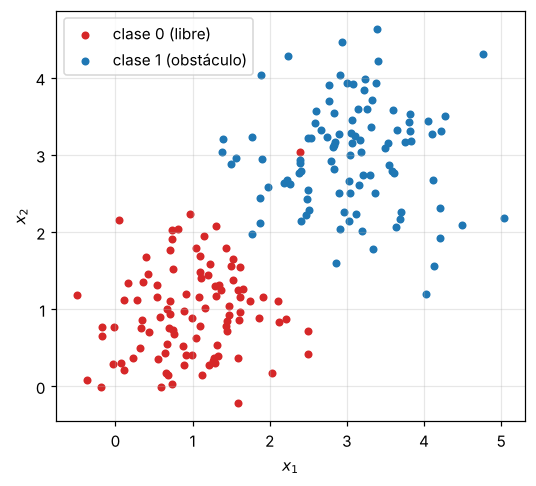

In [43]:
rng = np.random.default_rng(42)
n_clase = 100
X0 = rng.normal(loc=[1.0, 1.0], scale=0.7, size=(n_clase, 2))    # clase 0: sin obstáculo
X1 = rng.normal(loc=[3.0, 3.0], scale=0.7, size=(n_clase, 2))    # clase 1: con obstáculo

X = np.vstack([X0, X1])
y = np.concatenate([np.zeros(n_clase), np.ones(n_clase)])

print("X.shape =", X.shape, "| y.shape =", y.shape)
print("clase 0: media =", X0.mean(axis=0), "| clase 1: media =", X1.mean(axis=0))

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(*X0.T, s=18, c="tab:red", label="clase 0 (libre)")
ax.scatter(*X1.T, s=18, c="tab:blue", label="clase 1 (obstáculo)")
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.legend(); ax.set_aspect("equal")
plt.show()

## Paso 2 · La neurona

Una clase con los dos parámetros $w$ y $b$ y tres métodos:

- `suma(X)` calcula $s=Xw+b$ (conceptos 2, 6, 8),
- `forward(X)` calcula $z=\sigma(s)$ (concepto 7),
- `predecir(X)` devuelve la clase: $1$ si $z\ge0.5$.

**Nota geométrica.** $z\ge0.5\iff s\ge0$. Es decir, **clasificar es decidir de qué lado de la pared $w^\top x+b=0$ cae el punto**.

In [44]:
def sigmoide(s):
    return 1 / (1 + np.exp(-s))

class Neurona:
    def __init__(self, n_entradas, semilla=0):
        rng = np.random.default_rng(semilla)
        self.w = rng.normal(scale=0.1, size=n_entradas)    # pesos pequeños al azar, forma (n,)
        self.b = 0.0                                       # sesgo

    def suma(self, X):
        return X @ self.w + self.b          # (N, n) @ (n,) -> (N,)

    def forward(self, X):
        return sigmoide(self.suma(X))       # (N,), valores en (0, 1)

    def predecir(self, X):
        return (self.forward(X) >= 0.5).astype(int)

neurona = Neurona(n_entradas=2)
print("w =", neurona.w, "| b =", neurona.b)
print("forma de suma(X)   :", neurona.suma(X).shape)
print("forma de forward(X):", neurona.forward(X).shape)
print("primeras 5 salidas :", neurona.forward(X)[:5])

w = [ 0.0126 -0.0132] | b = 0.0
forma de suma(X)   : (200,)
forma de forward(X): (200,)
primeras 5 salidas : [0.5029 0.4993 0.4986 0.5009 0.5018]


## Paso 3 · Medir qué tan mal lo hace

Pérdida BCE (concepto 9) y exactitud (qué fracción de datos clasifica bien). Con pesos casi cero, la neurona dice $z\approx0.5$ para todo: **está adivinando**, y la BCE debería valer cerca de $\ln2\approx0.693$.

In [45]:
def bce(y, z, eps=1e-12):
    z = np.clip(z, eps, 1 - eps)
    return -np.mean(y * np.log(z) + (1 - y) * np.log(1 - z))

def exactitud(y, y_pred):
    return np.mean(y == y_pred)

print("pérdida inicial :", bce(y, neurona.forward(X)), "  (ln 2 =", np.log(2), ")")
print("exactitud inicial:", exactitud(y, neurona.predecir(X)))

pérdida inicial : 0.6933848680582944   (ln 2 = 0.6931471805599453 )
exactitud inicial: 0.48


## Paso 4 · El gradiente (y su verificación)

Del concepto 10, para el lote completo:

$$\nabla_wL=\frac{1}{N}X^\top(z-y),\qquad \frac{\partial L}{\partial b}=\frac{1}{N}\sum_i(z_i-y_i).$$

Formas: $X^\top\in\mathbb{R}^{n\times N}$, $(z-y)\in\mathbb{R}^N$, así que $\nabla_wL\in\mathbb{R}^n$, igual que $w$. **Antes de entrenar, comparamos con diferencias finitas.** Si no coincide, hay un error y no tiene sentido seguir.

In [46]:
def gradientes(neurona, X, y):
    z = neurona.forward(X)
    error = z - y                       # (N,)
    grad_w = X.T @ error / len(y)       # (n,)
    grad_b = error.mean()               # escalar
    return grad_w, grad_b

# --- Verificación con diferencias finitas (usa diferencias_finitas del concepto 10) ---
gw, gb = gradientes(neurona, X, y)

def perdida_con_w(w_nuevo):
    n2 = Neurona(2); n2.w = w_nuevo; n2.b = neurona.b
    return bce(y, n2.forward(X))

def perdida_con_b(b_nuevo):
    n2 = Neurona(2); n2.w = neurona.w.copy(); n2.b = b_nuevo[0]
    return bce(y, n2.forward(X))

num_w = diferencias_finitas(perdida_con_w, neurona.w.copy())
num_b = diferencias_finitas(perdida_con_b, np.array([neurona.b]))[0]

print("grad_w analítico:", gw, "| numérico:", num_w)
print("grad_b analítico:", gb, "| numérico:", num_b)
print("error relativo máximo:", max(np.max(np.abs(gw - num_w) / (np.abs(num_w) + 1e-12)), abs(gb - num_b) / (abs(num_b) + 1e-12)))

grad_w analítico: [-0.512  -0.5066] | numérico: [-0.512  -0.5066]
grad_b analítico: -0.00019529108725418353 | numérico: -0.0001952911721225803
error relativo máximo: 4.345736440834191e-07


## Paso 5 · Entrenar

El ciclo del aprendizaje, repetido muchas veces (cada pasada completa por los datos es una **época**):

1. calcular $z$ con los parámetros actuales,
2. calcular la pérdida (para vigilar el progreso),
3. calcular el gradiente,
4. dar un paso contrario al gradiente: $w\leftarrow w-\eta\nabla_wL$, $b\leftarrow b-\eta\,\partial L/\partial b$.

Guardamos una "foto" de la pared en algunas épocas para ver cómo se mueve.

pérdida: 0.6934 -> 0.0603
exactitud: 0.480 -> 0.990


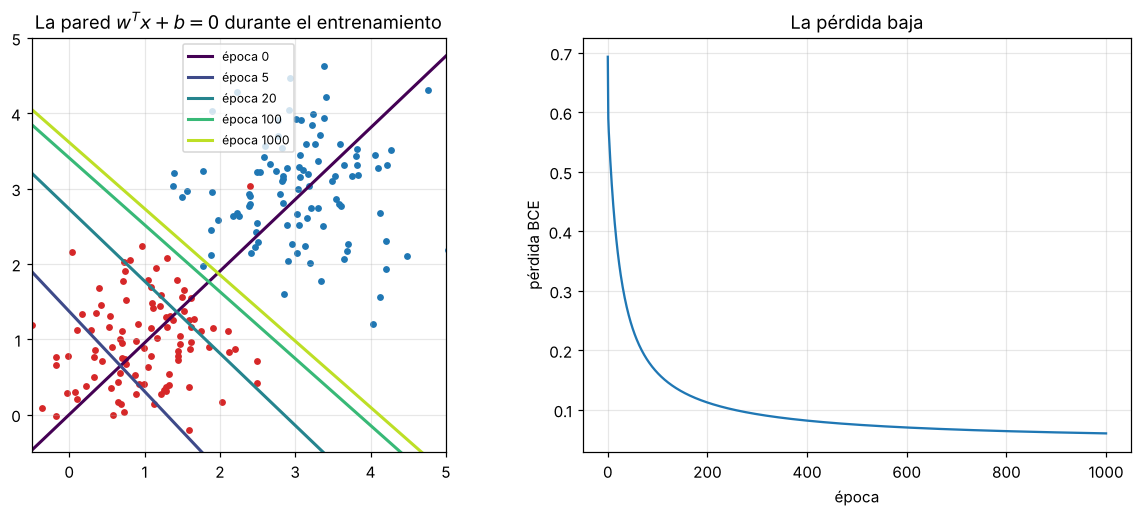

In [47]:
def entrenar(neurona, X, y, eta=0.5, epocas=1000, guardar=(0, 5, 20, 100, 1000)):
    historial = {"perdida": [], "exactitud": []}
    fotos = {}
    for epoca in range(epocas + 1):
        z = neurona.forward(X)
        historial["perdida"].append(bce(y, z))
        historial["exactitud"].append(exactitud(y, (z >= 0.5).astype(int)))
        if epoca in guardar:
            fotos[epoca] = (neurona.w.copy(), neurona.b)
        if epoca == epocas:
            break
        gw, gb = gradientes(neurona, X, y)
        neurona.w -= eta * gw
        neurona.b -= eta * gb
    return historial, fotos

neurona = Neurona(2)
historial, fotos = entrenar(neurona, X, y)

print(f"pérdida: {historial['perdida'][0]:.4f} -> {historial['perdida'][-1]:.4f}")
print(f"exactitud: {historial['exactitud'][0]:.3f} -> {historial['exactitud'][-1]:.3f}")

# --- Figura: la pared se mueve, y la pérdida baja ---
def dibujar_pared(ax, w, b, **kw):
    x1 = np.linspace(-1, 5, 100)
    ax.plot(x1, -(w[0] * x1 + b) / w[1], **kw)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.8))
ax1.scatter(*X0.T, s=12, c="tab:red"); ax1.scatter(*X1.T, s=12, c="tab:blue")
colores = plt.cm.viridis(np.linspace(0, 0.9, len(fotos)))
for (ep, (w_, b_)), c in zip(fotos.items(), colores):
    if abs(w_[1]) > 1e-9:
        dibujar_pared(ax1, w_, b_, color=c, lw=2, label=f"época {ep}")
ax1.set_xlim(-0.5, 5); ax1.set_ylim(-0.5, 5); ax1.set_aspect("equal"); ax1.legend(fontsize=8)
ax1.set_title("La pared $w^T x + b = 0$ durante el entrenamiento")
ax2.plot(historial["perdida"]); ax2.set_xlabel("época"); ax2.set_ylabel("pérdida BCE"); ax2.set_title("La pérdida baja")
plt.tight_layout(); plt.show()

## Paso 6 · Leer la pared que aprendió

Ahora usamos todo lo geométrico: la neurona aprendió un $w$ (la normal) y un $b$ (la posición). Calculemos la distancia de la pared al origen (concepto 6) y la distancia con signo de cada nube a la pared (concepto 5).

In [48]:
w, b = neurona.w, neurona.b
nw = np.linalg.norm(w)

print("w =", w, "| b =", b)
print("||w|| =", nw, "-> normal unitaria w/||w|| =", w / nw)
print("distancia de la pared al origen |b|/||w|| =", abs(b) / nw)

mu0 = X[y == 0].mean(axis=0); mu1 = X[y == 1].mean(axis=0)
t0 = (w @ mu0 + b) / nw; t1 = (w @ mu1 + b) / nw
print(f"\ncentro de la clase 0: distancia con signo = {t0:.3f}  (negativa: lado de la clase 0)")
print(f"centro de la clase 1: distancia con signo = {t1:.3f}  (positiva: lado de la clase 1)")

# La normal debería apuntar de la nube 0 hacia la nube 1:
direccion = (mu1 - mu0) / np.linalg.norm(mu1 - mu0)
print("\ncoseno entre la normal y la dirección nube0->nube1:", (w / nw) @ direccion)

w = [2.2887 2.6035] | b = -9.406725508872931
||w|| = 3.466471481597074 -> normal unitaria w/||w|| = [0.6602 0.7511]
distancia de la pared al origen |b|/||w|| = 2.7136312988038953

centro de la clase 0: distancia con signo = -1.333  (negativa: lado de la clase 0)
centro de la clase 1: distancia con signo = 1.538  (positiva: lado de la clase 1)

coseno entre la normal y la dirección nube0->nube1: 0.9973957735930696


## Paso 7 · Usarla con datos nuevos

El valor $z=\sigma(s)$ es la "confianza" de la neurona: cerca de $1$, obstáculo; cerca de $0$, libre; cerca de $0.5$, el punto está **cerca de la pared** (dudosa).

In [49]:
nuevos = np.array([[1.0, 1.5], [3.5, 2.5], [2.0, 2.0], [0.5, 0.5]])
probs = neurona.forward(nuevos)
clases = neurona.predecir(nuevos)
for p, pr, c in zip(nuevos, probs, clases):
    print(f"medidas {p} -> P(obstáculo) = {pr:.3f} -> clase {c}")

medidas [1.  1.5] -> P(obstáculo) = 0.039 -> clase 0
medidas [3.5 2.5] -> P(obstáculo) = 0.994 -> clase 1
medidas [2. 2.] -> P(obstáculo) = 0.593 -> clase 1
medidas [0.5 0.5] -> P(obstáculo) = 0.001 -> clase 0


## Paso 8 · Comparar con una librería

Primero con **scikit-learn** (`LogisticRegression` es, matemáticamente, exactamente esta neurona entrenada hasta el óptimo). Si todo está bien, su pared debería ser casi la misma que la nuestra.

> 🔎 **Nota.** Comparamos la **dirección** de $w$ (coseno) y las predicciones, no los números exactos: nuestro descenso se detuvo tras 1000 épocas y la librería usa un optimizador distinto.

In [50]:
try:
    from sklearn.linear_model import LogisticRegression
    modelo = LogisticRegression(C=1e10, max_iter=10000).fit(X, y)     # C enorme = sin regularización
    w_sk, b_sk = modelo.coef_[0], modelo.intercept_[0]
    print("nuestra neurona : w =", neurona.w, "| b =", neurona.b)
    print("scikit-learn    : w =", w_sk, "| b =", b_sk)
    coseno = (neurona.w @ w_sk) / (np.linalg.norm(neurona.w) * np.linalg.norm(w_sk))
    print("coseno entre los dos w:", coseno)
    print("predicciones iguales  :", np.mean(neurona.predecir(X) == modelo.predict(X)))
except ImportError:
    print("scikit-learn no está instalado. En tu proyecto: `uv add scikit-learn`.")

nuestra neurona : w = [2.2887 2.6035] | b = -9.406725508872931
scikit-learn    : w = [3.7386 3.9726] | b = -14.978853901274753
coseno entre los dos w: 0.9994247995487028
predicciones iguales  : 1.0


Y la versión con **PyTorch**, que es la librería que usarás en visión por computador. Aquí una neurona es `torch.nn.Linear(2, 1)` (guarda $w$ con forma $(1,2)$ y $b$ con forma $(1,)$), y el gradiente que dedujimos a mano lo calcula `.backward()` automáticamente.

> ⚠️ **Aviso de honestidad.** No pude ejecutar esta celda en mi entorno de trabajo (PyTorch no está instalado ahí), así que **su salida no está verificada por mí**. Si la ejecutas en tu Mac, cuéntame qué imprime. Para tenerla en tu proyecto: `uv add torch`. Mientras no esté instalada, la celda solo te avisa.

In [51]:
try:
    import torch

    Xt = torch.tensor(X, dtype=torch.float32)
    yt = torch.tensor(y, dtype=torch.float32)

    modelo_t = torch.nn.Linear(2, 1)                          # una neurona: w (1,2), b (1,)
    optimizador = torch.optim.SGD(modelo_t.parameters(), lr=0.5)
    perdida_fn = torch.nn.BCEWithLogitsLoss()                 # sigmoide + BCE en un solo paso (más estable)

    for epoca in range(1000):
        optimizador.zero_grad()
        s = modelo_t(Xt).squeeze(1)                           # (200, 1) -> (200,)
        perdida = perdida_fn(s, yt)
        perdida.backward()                                    # <- calcula los gradientes por ti
        optimizador.step()                                    # <- w <- w - lr * grad

    print("PyTorch: w =", modelo_t.weight.detach().numpy(), "| b =", modelo_t.bias.detach().numpy())
except ImportError:
    print("PyTorch aún no está instalado. En tu proyecto: `uv add torch` (lo haremos en la Sesión 0).")

PyTorch aún no está instalado. En tu proyecto: `uv add torch` (lo haremos en la Sesión 0).


---
# 🏆 Ejercicio unificador: construye tu neurona (y descubre su límite)

> 🎯 **Objetivo.** Construir tú mismo, paso a paso, una neurona completa para aprender la compuerta lógica **AND**, interpretar geométricamente la pared aprendida, y luego descubrir por qué **una sola neurona no puede aprender XOR**.

Las compuertas lógicas son un banco de pruebas clásico porque tienen solo 4 datos y se puede **ver** todo.

| $x_1$ | $x_2$ | AND | XOR |
|:--:|:--:|:--:|:--:|
| 0 | 0 | 0 | 0 |
| 0 | 1 | 0 | 1 |
| 1 | 0 | 0 | 1 |
| 1 | 1 | 1 | 0 |

**Pregunta geométrica para pensar antes de programar.** En el plano, dibuja los 4 puntos $(0,0),(0,1),(1,0),(1,1)$. Para AND, ¿puedes trazar **una recta** que deje el punto $(1,1)$ de un lado y los otros tres del otro? ¿Y para XOR (los puntos $(0,1),(1,0)$ de un lado y $(0,0),(1,1)$ del otro)?

Los pasos siguientes son **secuenciales**: cada uno usa las funciones del anterior, así que no te saltes ninguno. Tienen los prefijos `u_` para no chocar con lo que ya definimos.

#### ✏️ Ejercicio U1 · Datos

**Paso U1 · Los datos (conceptos 1 y 8).** Completa las etiquetas de AND como un arreglo de floats.

> ✅ **Resultado esperado:** Formas `(4, 2)` y `(4,)`.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
X_and = np.array([[0.0, 0.0], [0.0, 1.0], [1.0, 0.0], [1.0, 1.0]])    # (4, 2)
y_and = np.array(___)

print("X_and.shape =", X_and.shape, "| y_and.shape =", y_and.shape)
verificar("X_and tiene forma (4, 2)", X_and.shape == (4, 2))
verificar("y_and = [0, 0, 0, 1]", np.array_equal(y_and, [0, 0, 0, 1]))

#### ✏️ Ejercicio U2 · Suma ponderada y activación

**Paso U2 · La neurona (conceptos 2, 6, 7, 8).** Escribe `u_suma` ($s=Xw+b$) y `u_forward` ($z=\sigma(s)$). Se prueba con $w=(1,1)$ y $b=-1.5$, una pared que ya separa AND: $s=(-1.5,-0.5,-0.5,0.5)$.

> ✅ **Resultado esperado:** `s = [-1.5 -0.5 -0.5  0.5]` y tres ✅.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
def u_suma(X, w, b):
    return ___

def u_forward(X, w, b):
    s = u_suma(X, w, b)
    return ___

w_prueba = np.array([1.0, 1.0]); b_prueba = -1.5
print("s =", u_suma(X_and, w_prueba, b_prueba))
print("z =", u_forward(X_and, w_prueba, b_prueba))
verificar("s = [-1.5, -0.5, -0.5, 0.5]", np.allclose(u_suma(X_and, w_prueba, b_prueba), [-1.5, -0.5, -0.5, 0.5]))
verificar("z tiene forma (4,)", u_forward(X_and, w_prueba, b_prueba).shape == (4,))
verificar("solo (1,1) queda con z > 0.5", np.array_equal(u_forward(X_and, w_prueba, b_prueba) > 0.5, [False, False, False, True]))

#### ✏️ Ejercicio U3 · Pérdida BCE

**Paso U3 · La pérdida (concepto 9).** Escribe `u_perdida(y, z)`: la BCE promediada, con el recorte $\varepsilon$ para evitar $\ln0$.

> ✅ **Resultado esperado:** `0.6931...` (que es $\ln2$) y dos ✅.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
def u_perdida(y, z, eps=1e-12):
    z = np.clip(z, eps, 1 - eps)
    return -np.mean(___)

z_ini = u_forward(X_and, np.zeros(2), 0.0)       # una neurona "en blanco" dice 0.5 para todo
L_ini = u_perdida(y_and, z_ini)
print("pérdida de una neurona en blanco:", L_ini, "| ln 2 =", np.log(2))
verificar("la pérdida en blanco es ln 2", np.isclose(L_ini, np.log(2)))
verificar("acertar con seguridad da pérdida ~0", u_perdida(np.array([1.0]), np.array([1.0])) < 1e-9)

#### ✏️ Ejercicio U4 · Gradiente

**Paso U4 · El gradiente (concepto 10).** Escribe `u_gradientes(X, y, w, b)` con $\nabla_wL=\frac1NX^\top(z-y)$ y $\partial L/\partial b=\frac1N\sum(z-y)$. La celda lo compara con diferencias finitas.

> 💡 **Pista:** Forma de las piezas: $X^\top$ es $(2,4)$ y `error` es $(4,)$, así que `X.T @ error` es $(2,)$, igual que $w$.

> ✅ **Resultado esperado:** Tres ✅ (el análisis y el numérico coinciden).

In [ ]:
# ✏️ Rellena los ___ y ejecuta
def u_gradientes(X, y, w, b):
    z = u_forward(X, w, b)
    error = ___
    grad_w = ___
    grad_b = ___
    return grad_w, grad_b

w0 = np.array([0.3, -0.2]); b0 = 0.1
gw, gb = u_gradientes(X_and, y_and, w0, b0)
num_w = diferencias_finitas(lambda ww: u_perdida(y_and, u_forward(X_and, ww, b0)), w0)
num_b = diferencias_finitas(lambda bb: u_perdida(y_and, u_forward(X_and, w0, bb[0])), np.array([b0]))[0]

print("grad_w =", gw, "| numérico =", num_w)
print("grad_b =", gb, "| numérico =", num_b)
verificar("grad_w tiene forma (2,)", gw.shape == (2,))
verificar("grad_w coincide con diferencias finitas", np.allclose(gw, num_w, atol=1e-6))
verificar("grad_b coincide con diferencias finitas", np.isclose(gb, num_b, atol=1e-6))

#### ✏️ Ejercicio U5 · Entrenamiento

**Paso U5 · Entrenar (conceptos 9 y 10).** Completa las dos líneas de actualización del descenso de gradiente. Partimos de $w=0$, $b=0$.

> ✅ **Resultado esperado:** La pérdida baja de $0.693$ a casi $0$; predicciones `[0 0 0 1]`.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
def u_entrenar(X, y, eta=1.0, epocas=3000):
    w = np.zeros(X.shape[1])
    b = 0.0
    historial = []
    for epoca in range(epocas):
        historial.append(u_perdida(y, u_forward(X, w, b)))
        grad_w, grad_b = u_gradientes(X, y, w, b)
        w = ___
        b = ___
    return w, b, historial

w_and, b_and, hist_and = u_entrenar(X_and, y_and)
pred_and = (u_forward(X_and, w_and, b_and) >= 0.5).astype(int)

print("w =", w_and, "| b =", b_and)
print("pérdida:", hist_and[0], "->", hist_and[-1])
print("predicciones:", pred_and)
verificar("la pérdida bajó", hist_and[-1] < hist_and[0])
verificar("AND aprendido: exactitud 100%", np.array_equal(pred_and, y_and.astype(int)))

#### ✏️ Ejercicio U6 · Interpretación geométrica

**Paso U6 · Leer la pared (conceptos 3 a 6).** Con el $w$ y $b$ que aprendió tu neurona, calcula: (a) la distancia de la pared al origen, y (b) la **distancia con signo** de los 4 puntos a la pared (con una sola expresión matricial). Debe quedar positiva solo para $(1,1)$.

> ✅ **Resultado esperado:** Tres ✅. Observa que $w_1\approx w_2$ y $b<0$: la pared es una diagonal desplazada.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
nw = np.linalg.norm(w_and)

dist_origen = ___
t_puntos = ___

print("w =", w_and, "| b =", b_and)
print("distancia de la pared al origen:", dist_origen)
print("distancias con signo:", t_puntos)
verificar("t_puntos tiene forma (4,)", t_puntos.shape == (4,))
verificar("solo (1,1) cae del lado positivo", np.array_equal(t_puntos > 0, [False, False, False, True]))
verificar("la pared NO pasa por el origen (necesitó sesgo)", dist_origen > 0.1)

#### ✏️ Ejercicio U7 · XOR

**Paso U7 · El límite: XOR.** Entrena **la misma neurona** con las etiquetas de XOR y mide la exactitud. Verifica que **no llega a 100%**.

> ✅ **Resultado esperado:** La pérdida se queda cerca de $\ln2\approx0.693$ y la exactitud **no** llega a $1$.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
y_xor = np.array([0.0, 1.0, 1.0, 0.0])

w_xor, b_xor, hist_xor = u_entrenar(X_and, y_xor)          # mismos puntos, otras etiquetas
pred_xor = ___
acc_xor = ___

print("w =", w_xor, "| b =", b_xor)
print("pérdida final:", hist_xor[-1], "(ln 2 =", np.log(2), ")")
print("predicciones:", pred_xor, "| exactitud:", acc_xor)
verificar("una sola neurona NO aprende XOR (exactitud <= 75%)", acc_xor <= 0.75)

### ✍️ Para escribir con tus propias palabras

En una celda de texto (o en tu cuaderno de Obsidian), responde:

1. **¿Por qué la neurona aprende AND y no XOR?** Usa el lenguaje de la pared: ¿cuántas paredes planas puede trazar una sola neurona? ¿Cómo quedan los 4 puntos de XOR en el plano?
2. **¿Qué pasaría si usáramos dos neuronas** y combináramos sus salidas con una tercera? (Pista: dos paredes dividen el plano en más regiones.)
3. **¿Qué teorema de este cuaderno te dice que apilar neuronas *sin* activación no resolvería XOR?** (Pista: concepto 7.)

> 🟦 **Resultado conocido (Minsky y Papert, 1969).** Un perceptrón de una sola capa (una neurona con umbral) no puede representar XOR, porque XOR no es linealmente separable. Con una **capa oculta** (varias neuronas) sí se puede. Ese es exactamente el tema que sigue en la ruta.

---
# 🎓 Cierre

## De la figura 1.02 al código

| En la figura | En matemáticas | En el código |
|---|---|---|
| Dendritas $x_1,\dots,x_n$ | $x\in\mathbb{R}^n$ | `X` (forma `(N, n)`) |
| Peso de cada cable | $w\in\mathbb{R}^n$ | `neurona.w` |
| Cuerpo celular $\Sigma$ | $s=w^\top x+b$ | `X @ w + b` |
| Sesgo $b$ | $b\in\mathbb{R}$ | `neurona.b` |
| $f$ | $\sigma(s)$, ReLU, ... | `sigmoide(s)` |
| Axón (salida $z$) | $z=f(s)$ | `neurona.forward(X)` |
| "Aprender" | $w\leftarrow w-\eta\nabla L$ | `entrenar(...)` |

## Lo que debes llevarte

1. Una neurona es **una pared** (un hiperplano) más **una decisión**.
2. $w$ es la **normal** de la pared; $b$ la **posición**; $s/\lVert w\rVert$ la **distancia con signo**.
3. La activación convierte esa distancia en una respuesta, y **sin no linealidad las capas colapsan**.
4. Aprender es **minimizar una pérdida** moviendo $w$ y $b$ contra el gradiente.
5. Un gradiente **siempre se verifica** con diferencias finitas.
6. Una neurona sola tiene un límite claro (XOR): de ahí nacen las **capas**.

## Estatus de lo que afirmamos

| Afirmación | Tipo |
|---|---|
| $x\perp y\iff x\cdot y=0$ | 🟦 Teorema |
| $w\perp H$, $\dim H=n-1$ | 🟦 Teorema |
| $t=(w^\top x+b)/\lVert w\rVert$ es la distancia con signo | 🟦 Teorema |
| Composición de funciones afines es afín | 🟦 Teorema |
| Aproximación universal (existencia de la red) | 🟦 Teorema (no constructivo) |
| $\nabla_wL=(z-y)x$ para sigmoide + BCE | 🟦 Resultado derivado arriba |
| BCE es la log-verosimilitud negativa de Bernoulli | 📘/🟦 Con supuestos (independencia, modelo correcto) |
| La pérdida BCE de esta neurona es convexa | 🟦 Resultado conocido (no lo demostramos aquí) |
| ReLU como activación por defecto | 🟧 Práctica empírica |
| Valores típicos de $\eta$ ($0.1$, $0.01$) | 🟨 Heurística |
| "Un $\lVert w\rVert$ grande = más seguridad" | 🟨 Heurística |
| "Se parece a una neurona biológica" | Analogía, no un modelo fiel |

## ➡️ Lo que sigue

- **Capas** ($Y=XW^\top+\mathbf 1b^\top$): varias neuronas en paralelo, que resuelven XOR.
- **Retropropagación**: la regla de la cadena de este cuaderno, aplicada capa por capa.
- **Convoluciones**: el mismo $w^\top x+b$ aplicado a cada parche de una imagen. Es el puente hacia la visión por computador y la robótica.